# Exploracion general de produccion y paradas

**Pregunta:** durante el tiempo en que estaba previsto producir, donde se pierde
capacidad y que evidencia justifica una investigacion?

El analisis admite otras lineas y operaciones con el mismo contrato de datos diarios.
Las rutas, nombres de columnas, unidades, objetivos y calendario son configurables.
No se codifican nombres de maquinas ni fechas festivas. La configuracion puede tener
operaciones paralelas: su orden no sustituye a un grafo de conexiones.

Separaremos hechos observados, problemas de calidad e hipotesis. Un dia sin actividad
no demuestra que sea festivo; una maquina parada no demuestra que estuviera inactiva
por planificacion. Los datos originales se conservan sin cambios.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython import get_ipython
from IPython.display import display

# Mostrar las figuras dentro del notebook, incluso si el kernel usaba Agg.
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
if not (ROOT / 'data').exists() and (ROOT.parent / 'data').exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / 'data' / 'datos_hackaton.csv'
CONFIG_PATH = ROOT / 'data' / 'config_hackaton.csv'
CONNECTIONS_PATH = None  # CSV opcional: Linea, Origen, Destino
CALENDAR_PATH = None  # CSV opcional, definido en la siguiente seccion
CSV_OPTIONS = {'sep': ',', 'decimal': '.', 'encoding': 'utf-8-sig'}
COLUMN_MAP = {}  # Ejemplo: {'Machine': 'Operacion', 'Day': 'Jour'}
CONFIG_COLUMN_MAP = {}
TIME_UNIT = 'hours'  # 'hours', 'minutes' o 'seconds'; confirmar con el propietario
REFERENCE_HOURS = 22.0  # referencia configurable, NO denominador obligatorio
TIME_TOLERANCE_HOURS = 0.10  # tolerancia exploratoria, no regla de correccion
AVAILABILITY_TARGET = 90.0
CYCLE_TARGET_CMIN = 80.0
STOP_RATE_BASE = 1000  # Fpm por mil segun presentacion/README; usar 100 si se acuerda
MICROSTOP_MEAN_SECONDS = 60.0  # hipotesis exploratoria, no umbral validado
TOP_N = 10
DAY_KEYS = ['Linea', 'Year', 'Week', 'Jour']
JOIN_KEYS = ['Linea', 'Operacion']
ROW_KEYS = DAY_KEYS + ['Operacion']
TIMES = ['TBF', 'TAP', 'DES', 'SAT']
COUNTERS = ['NAP', 'NPR']
VALUES = TIMES + COUNTERS
FLAGS = ['production_without_runtime', 'runtime_without_production',
         'stops_without_own_time', 'own_time_without_stops']
COLORS = {'TBF': '#2a9d8f', 'TAP': '#e76f51', 'DES': '#457b9d', 'SAT': '#b39ddb'}
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.figsize': (11, 5), 'axes.spines.top': False, 'axes.spines.right': False})
raw_data = pd.read_csv(DATA_PATH, **CSV_OPTIONS).rename(columns=lambda col: col.strip()).rename(columns=COLUMN_MAP)
raw_config = pd.read_csv(CONFIG_PATH, **CSV_OPTIONS).rename(columns=lambda col: col.strip()).rename(columns=CONFIG_COLUMN_MAP)
print(f'Entrada: {len(raw_data)} registros; {len(raw_config)} operaciones configuradas.')

Entrada: 1820 registros; 91 operaciones configuradas.


## 1. Contrato, duplicados y calidad

Se espera una fila por **linea, operacion, anio, semana y dia**. Otros formatos
(por turno o por evento) requieren adaptar la clave antes de usar el analisis.

- Normalizamos espacios en cabeceras e identificadores; no cambiamos guiones ni nombres.
- Eliminamos solo copias completamente identicas y contamos cuantas eran.
- Si quedan varias filas para una misma clave diaria, las apartamos para revision:
  no sabemos si son correcciones, turnos o duplicados y no las sumamos arbitrariamente.
- Apartamos registros incompletos, negativos, no finitos o con contadores no enteros.
- Comprobamos la union con configuracion. Repetir un numero de orden puede representar
  paralelismo y no se elimina como duplicado.

Los registros apartados quedan disponibles en `quarantine`; las incidencias en `audit`.
Apartar no significa corregir ni asumir que el resto del periodo esta completo.

El detalle de cada senal muestra **linea, operacion, orden, anio, semana y dia**,
con todos los tiempos (en horas) y contadores que permiten comprobarla. Se muestran
todos los registros, sin limitarse a los primeros. Una fila puede aparecer en varias
senales. Este detalle es anterior al tratamiento del calendario del punto 2.


In [2]:
def prepare_data(source, configuration, time_unit):
    data, config = source.copy(), configuration.copy()
    data.columns = data.columns.str.strip()
    config.columns = config.columns.str.strip()
    if data.columns.duplicated().any() or config.columns.duplicated().any():
        raise ValueError('Hay nombres de columnas repetidos despues de normalizar.')
    for frame, required in [(data, ROW_KEYS + VALUES), (config, JOIN_KEYS + ['Orden_OP'])]:
        missing = set(required) - set(frame.columns)
        if missing:
            raise ValueError(f'Faltan columnas requeridas: {sorted(missing)}')
        for col in JOIN_KEYS:
            frame[col] = frame[col].astype('string').str.strip().replace('', pd.NA)
    duplicate_copies = data.duplicated().sum()
    data = data.drop_duplicates().copy()
    numeric_cols = ['Year', 'Week', 'Jour'] + VALUES
    for col in numeric_cols:
        data[col] = pd.to_numeric(data[col], errors='coerce')
    config['Orden_OP'] = pd.to_numeric(config['Orden_OP'], errors='coerce')
    if config[JOIN_KEYS].isna().any().any() or not np.isfinite(config['Orden_OP']).all():
        raise ValueError('Configuracion incompleta o con orden no numerico.')
    if config.duplicated(JOIN_KEYS).any():
        raise ValueError('Configuracion ambigua: claves Linea + Operacion repetidas.')
    factors = {'hours': 1, 'minutes': 1/60, 'seconds': 1/3600}
    if time_unit not in factors:
        raise ValueError('TIME_UNIT debe ser hours, minutes o seconds.')
    bad_key = data[ROW_KEYS].isna().any(axis=1)
    date_invalid = (data[['Year', 'Week', 'Jour']].mod(1).ne(0).any(axis=1)
                    | ~data['Year'].between(1, 9999) | ~data['Week'].between(1, 53)
                    | ~data['Jour'].between(1, 7))
    bad_numeric = ~np.isfinite(data[numeric_cols]).all(axis=1) | data[VALUES].lt(0).any(axis=1)
    bad_counter = data[COUNTERS].mod(1).ne(0).any(axis=1)
    repeated_key = data.duplicated(ROW_KEYS, keep=False)
    known_keys = pd.MultiIndex.from_frame(config[JOIN_KEYS])
    unknown = ~pd.MultiIndex.from_frame(data[JOIN_KEYS]).isin(known_keys)
    issues = pd.DataFrame({'invalid_key_or_day': bad_key | date_invalid,
                           'invalid_numeric': bad_numeric | bad_counter,
                           'conflicting_daily_key': repeated_key,
                           'operation_not_configured': unknown}, index=data.index)
    excluded = issues.any(axis=1)
    quarantine = data.loc[excluded].join(issues.add_prefix('issue_'))
    clean = data.loc[~excluded].copy()
    clean[TIMES] = clean[TIMES] * factors[time_unit]
    clean = clean.merge(config[JOIN_KEYS + ['Orden_OP']], on=JOIN_KEYS, validate='many_to_one')
    clean['production_without_runtime'] = clean.NPR.gt(0) & clean.TBF.eq(0)
    clean['runtime_without_production'] = clean.TBF.gt(0) & clean.NPR.eq(0)
    clean['stops_without_own_time'] = clean.NAP.gt(0) & clean.TAP.eq(0)
    clean['own_time_without_stops'] = clean.TAP.gt(0) & clean.NAP.eq(0)
    audit = pd.Series({'input_rows': len(source), 'identical_copies_removed': int(duplicate_copies),
                       'quarantined_rows': int(excluded.sum()), 'usable_rows': len(clean),
                       **issues.sum().astype(int).to_dict()}, name='Registros')
    return clean, config, quarantine, audit

clean, config, quarantine, audit = prepare_data(raw_data, raw_config, TIME_UNIT)
display(audit.to_frame())
if clean.empty:
    raise ValueError('No quedan registros utilizables: revisar quarantine antes de continuar.')
display(clean[FLAGS].sum().rename('Registros con senal de revision').to_frame())

,Registros
input_rows,1820
identical_copies_removed,0
quarantined_rows,0
usable_rows,1820
invalid_key_or_day,0
invalid_numeric,0
conflicting_daily_key,0
operation_not_configured,0


,Registros con senal de revision
production_without_runtime,4
runtime_without_production,65
stops_without_own_time,16
own_time_without_stops,364


In [3]:
# Localizacion exacta de todos los registros que activan cada senal.
REVIEW_LABELS = {
    'production_without_runtime': 'Produccion sin tiempo de funcionamiento (NPR > 0 y TBF = 0)',
    'runtime_without_production': 'Funcionamiento sin produccion (TBF > 0 y NPR = 0)',
    'stops_without_own_time': 'Paradas propias sin tiempo registrado (NAP > 0 y TAP = 0)',
    'own_time_without_stops': 'Tiempo de parada propia sin paradas contadas (TAP > 0 y NAP = 0)',
}
REVIEW_COLUMNS = ['Linea', 'Operacion', 'Orden_OP', 'Year', 'Week', 'Jour'] + VALUES
REVIEW_ORDER = ['Linea', 'Year', 'Week', 'Jour', 'Orden_OP', 'Operacion']
review_records = {}
for signal in FLAGS:
    detail = (clean.loc[clean[signal], REVIEW_COLUMNS]
              .sort_values(REVIEW_ORDER).reset_index(drop=True))
    review_records[signal] = detail
    print(f'{signal}: {REVIEW_LABELS[signal]}')
    print(f'Registros: {len(detail)} | Tiempos en horas; Year = anio, Week = semana, Jour = dia.')
    if detail.empty:
        print('No se han encontrado registros con esta senal.')
    else:
        # Mostrar todas las filas; el resumen anterior sigue disponible para consultar cantidades.
        with pd.option_context('display.max_rows', None, 'display.max_columns', None):
            display(detail)

production_without_runtime: Produccion sin tiempo de funcionamiento (NPR > 0 y TBF = 0)
Registros: 4 | Tiempos en horas; Year = anio, Week = semana, Jour = dia.


,Linea,Operacion,Orden_OP,Year,Week,Jour,TBF,TAP,DES,SAT,NAP,NPR
0,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,42,4,0.0,22.00,0.0,0.0,12,1509
1,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,43,3,0.0,22.00,0.0,0.0,12,1541
2,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,43,4,0.0,22.01,0.0,0.0,12,1513
3,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,43,5,0.0,22.00,0.0,0.0,12,1531


runtime_without_production: Funcionamiento sin produccion (TBF > 0 y NPR = 0)
Registros: 65 | Tiempos en horas; Year = anio, Week = semana, Jour = dia.


,Linea,Operacion,Orden_OP,Year,Week,Jour,TBF,TAP,DES,SAT,NAP,NPR
0,VLL_MONTAJE_L5,Ma_BM1_2,86,2026,40,2,22.00,0.00,0.00,0.00,0,0
1,VLL_MONTAJE_L5,ManBM2_1,87,2026,40,2,0.29,21.72,0.00,0.00,13,0
2,VLL_MONTAJE_L5,Ma_VES_0,89,2026,40,2,22.00,0.00,0.00,0.00,0,0
3,VLL_MONTAJE_L5,Ma_VESRE,90,2026,40,2,22.00,0.00,0.00,0.00,1,0
4,VLL_MONTAJE_L5,ST-0295,25,2026,40,3,18.86,0.07,0.67,2.40,2,0
5,VLL_MONTAJE_L5,Ma_BM1_2,86,2026,40,3,22.00,0.00,0.00,0.00,0,0
6,VLL_MONTAJE_L5,ManBM2_1,87,2026,40,3,0.34,21.67,0.00,0.00,13,0
7,VLL_MONTAJE_L5,Ma_VES_0,89,2026,40,3,22.00,0.00,0.00,0.00,0,0
8,VLL_MONTAJE_L5,Ma_VESRE,90,2026,40,3,22.01,0.00,0.00,0.00,0,0
9,VLL_MONTAJE_L5,Ma_BM1_2,86,2026,40,4,21.98,0.03,0.00,0.00,2,0


stops_without_own_time: Paradas propias sin tiempo registrado (NAP > 0 y TAP = 0)
Registros: 16 | Tiempos en horas; Year = anio, Week = semana, Jour = dia.


,Linea,Operacion,Orden_OP,Year,Week,Jour,TBF,TAP,DES,SAT,NAP,NPR
0,VLL_MONTAJE_L5,Ma_VESRE,90,2026,40,2,22.00,0.0,0.00,0.00,1,0
1,VLL_MONTAJE_L5,ST-0240,16,2026,40,4,19.55,0.0,0.02,2.43,1,1497
2,VLL_MONTAJE_L5,Ma_BM2_2,88,2026,40,5,8.70,0.0,13.29,0.00,1051,1459
3,VLL_MONTAJE_L5,Ma_VES_0,89,2026,41,1,22.01,0.0,0.00,0.00,2,0
4,VLL_MONTAJE_L5,PM_2310,68,2026,41,3,19.70,0.0,1.49,0.00,3,1550
5,VLL_MONTAJE_L5,ManutPul,34,2026,42,2,13.83,0.0,8.07,0.10,1261,1539
6,VLL_MONTAJE_L5,PM_2310,68,2026,42,2,18.72,0.0,2.21,0.00,2,1533
7,VLL_MONTAJE_L5,Ma_VES_0,89,2026,42,2,22.00,0.0,0.00,0.00,1,0
8,VLL_MONTAJE_L5,ManutPul,34,2026,42,3,13.43,0.0,8.04,0.52,1221,1510
9,VLL_MONTAJE_L5,PM_2310,68,2026,42,3,19.11,0.0,1.82,0.00,1,1516


own_time_without_stops: Tiempo de parada propia sin paradas contadas (TAP > 0 y NAP = 0)
Registros: 364 | Tiempos en horas; Year = anio, Week = semana, Jour = dia.


,Linea,Operacion,Orden_OP,Year,Week,Jour,TBF,TAP,DES,SAT,NAP,NPR
0,VLL_MONTAJE_L5,ST_0015,1,2026,40,1,0.0,22.0,0.0,0.0,0,0
1,VLL_MONTAJE_L5,ST_0020,2,2026,40,1,0.0,22.0,0.0,0.0,0,0
2,VLL_MONTAJE_L5,ST_0030,3,2026,40,1,0.0,22.0,0.0,0.0,0,0
3,VLL_MONTAJE_L5,ST_0040,4,2026,40,1,0.0,22.0,0.0,0.0,0,0
4,VLL_MONTAJE_L5,ST-0050,5,2026,40,1,0.0,22.0,0.0,0.0,0,0
5,VLL_MONTAJE_L5,PM_0090,6,2026,40,1,0.0,22.0,0.0,0.0,0,0
6,VLL_MONTAJE_L5,ST_0095,7,2026,40,1,0.0,22.0,0.0,0.0,0,0
7,VLL_MONTAJE_L5,ST_0100,8,2026,40,1,0.0,22.0,0.0,0.0,0,0
8,VLL_MONTAJE_L5,PM_0110,9,2026,40,1,0.0,22.0,0.0,0.0,0,0
9,VLL_MONTAJE_L5,ST_0115,10,2026,40,1,0.0,22.0,0.0,0.0,0,0


### 1.1 Catalogo de nombres e identificadores

Se conservan los nombres originales de configuracion. `ST-0050`, `ST_0015` y
`ST0261` usan convenciones distintas, pero eso no demuestra errores ni diferencias
funcionales. Tampoco permite deducir zonas o conexiones. El significado del separador
y de los sufijos requiere el diccionario de activos de la empresa.

La tabla siguiente muestra TODAS las operaciones con su orden, formato, sufijo y
presencia en produccion. Se busca si cambiar separadores o mayusculas uniria claves
que hoy son distintas, pero esa clave auxiliar se usa solo para auditar: no modifica
`Operacion`. Dos codigos con el mismo numero base y distinto sufijo no se fusionan.


In [4]:
identifier_catalog = config.copy().sort_values(['Linea','Orden_OP','Operacion'])
st_parts = identifier_catalog.Operacion.str.extract(r'^ST([-_]?)([0-9]+)(.*)$')
identifier_catalog['Formato_ST'] = st_parts[0].map({'-':'ST-numero', '_':'ST_numero', '':'STnumero'})
identifier_catalog['Formato_ST'] = identifier_catalog.Formato_ST.fillna('Otro prefijo')
identifier_catalog['Numero_ST'] = st_parts[1].fillna('')
identifier_catalog['Sufijo_ST'] = st_parts[2].fillna('')
raw_identifiers = raw_data[JOIN_KEYS].copy()
for col in JOIN_KEYS:
    raw_identifiers[col] = raw_identifiers[col].astype('string').str.strip()
raw_counts = raw_identifiers.groupby(JOIN_KEYS).size().rename('Registros_en_origen').reset_index()
usable_counts = clean.groupby(JOIN_KEYS).size().rename('Registros_utilizables').reset_index()
identifier_catalog = identifier_catalog.merge(raw_counts,on=JOIN_KEYS,how='left',validate='one_to_one')
identifier_catalog = identifier_catalog.merge(usable_counts,on=JOIN_KEYS,how='left',validate='one_to_one')
identifier_catalog[['Registros_en_origen','Registros_utilizables']] = identifier_catalog[['Registros_en_origen','Registros_utilizables']].fillna(0).astype(int)
print('TODOS los nombres originales, sin reemplazar guiones, guiones bajos ni sufijos:')
with pd.option_context('display.max_rows',None,'display.max_columns',None):
    display(identifier_catalog)
print('Formatos de identificadores ST:')
display(identifier_catalog.loc[identifier_catalog.Numero_ST.ne('')].groupby('Formato_ST').size().rename('Operaciones').to_frame())
# Normalizacion hipotetica para detectar colisiones; nunca se usa para unir datos.
identifier_check = identifier_catalog[JOIN_KEYS].copy()
identifier_check['Clave_solo_auditoria'] = identifier_check.Operacion.str.upper().str.replace(r'[-_\s]','',regex=True)
identifier_collisions = identifier_check.loc[identifier_check.duplicated(['Linea','Clave_solo_auditoria'],keep=False)]
print('Claves distintas que colisionarian si quitasemos separadores y mayusculas:')
display(identifier_collisions)
identifier_presence = raw_identifiers.drop_duplicates().merge(config[JOIN_KEYS],on=JOIN_KEYS,how='left',indicator=True,validate='one_to_one')
identifier_unmatched = identifier_presence.loc[identifier_presence['_merge'].eq('left_only'),JOIN_KEYS]
print('Nombres de produccion sin correspondencia exacta en configuracion (tras strip):')
display(identifier_unmatched)
st_catalog=identifier_catalog.loc[identifier_catalog.Numero_ST.ne('')]
base_number_variants=st_catalog.loc[st_catalog.duplicated(['Linea','Numero_ST'],keep=False)]
print('Mismo numero ST con sufijos o identificadores diferentes; no implica duplicado ni paralelo:')
display(base_number_variants[['Linea','Operacion','Orden_OP','Numero_ST','Sufijo_ST']])
print(f'Catalogo: {len(identifier_catalog)} operaciones; formatos ST distintos: '
      f'{st_catalog.Formato_ST.nunique()}; nombres de produccion sin correspondencia: {len(identifier_unmatched)}.')

TODOS los nombres originales, sin reemplazar guiones, guiones bajos ni sufijos:


,Linea,Operacion,Orden_OP,Formato_ST,Numero_ST,Sufijo_ST,Registros_en_origen,Registros_utilizables
0,VLL_MONTAJE_L5,ST_0015,1,ST_numero,0015,,20,20
1,VLL_MONTAJE_L5,ST_0020,2,ST_numero,0020,,20,20
2,VLL_MONTAJE_L5,ST_0030,3,ST_numero,0030,,20,20
3,VLL_MONTAJE_L5,ST_0040,4,ST_numero,0040,,20,20
4,VLL_MONTAJE_L5,ST-0050,5,ST-numero,0050,,20,20
5,VLL_MONTAJE_L5,PM_0090,6,Otro prefijo,,,20,20
6,VLL_MONTAJE_L5,ST_0095,7,ST_numero,0095,,20,20
7,VLL_MONTAJE_L5,ST_0100,8,ST_numero,0100,,20,20
8,VLL_MONTAJE_L5,PM_0110,9,Otro prefijo,,,20,20
9,VLL_MONTAJE_L5,ST_0115,10,ST_numero,0115,,20,20


Formatos de identificadores ST:


,Operaciones
Formato_ST,
ST-numero,38
ST_numero,16
STnumero,7


Claves distintas que colisionarian si quitasemos separadores y mayusculas:


,Linea,Operacion,Clave_solo_auditoria


Nombres de produccion sin correspondencia exacta en configuracion (tras strip):


,Linea,Operacion


Mismo numero ST con sufijos o identificadores diferentes; no implica duplicado ni paralelo:


,Linea,Operacion,Orden_OP,Numero_ST,Sufijo_ST
81,VLL_MONTAJE_L5,ST_3100,82,3100,
82,VLL_MONTAJE_L5,ST3100_2,83,3100,_2


Catalogo: 91 operaciones; formatos ST distintos: 3; nombres de produccion sin correspondencia: 0.


## 2. Calendario, cobertura y dias sin actividad

El calendario de fabrica es preferible al calendario de festivos civiles: puede
haber turnos especiales, puentes y cierres. CSV opcional con estas columnas:
`Linea, Year, Week, Jour, Planned_Production` (0 o 1), y `Planned_Hours` opcional.
Cada clave diaria debe ser unica. Un calendario parcial deja el resto como desconocido.
No convertimos `Jour` a una fecha hasta confirmar que usa dias ISO de la semana.

Sin calendario, un dia con cobertura completa, TBF cero y NPR cero en toda la linea
se marca **sin actividad, pendiente de confirmar**. No se etiqueta como festivo.
Si el calendario indica produccion prevista, ese dia se conserva aunque todo se pare.
Si faltan operaciones, tampoco afirmamos que la linea entera estuviese cerrada.

In [5]:
def classify_days(clean, config, calendar=None):
    days = clean.groupby(DAY_KEYS, as_index=False).agg(
        observed_operations=('Operacion', 'nunique'),
        all_zero_runtime=('TBF', lambda s: s.eq(0).all()),
        all_zero_output=('NPR', lambda s: s.eq(0).all()))
    expected = config.groupby('Linea').size().rename('expected_operations')
    days = days.join(expected, on='Linea')
    days['complete_coverage'] = days.observed_operations.eq(days.expected_operations)
    days['no_activity_signal'] = days.complete_coverage & days.all_zero_runtime & days.all_zero_output
    if calendar is not None:
        calendar = calendar.copy()
        calendar.columns = calendar.columns.str.strip()
        if not set(DAY_KEYS + ['Planned_Production']).issubset(calendar.columns):
            raise ValueError('Calendario sin columnas requeridas.')
        calendar['Linea'] = calendar['Linea'].astype('string').str.strip()
        for col in ['Year', 'Week', 'Jour', 'Planned_Production']:
            calendar[col] = pd.to_numeric(calendar[col], errors='coerce')
        if calendar[DAY_KEYS].isna().any().any() or calendar.duplicated(DAY_KEYS).any():
            raise ValueError('Calendario con claves incompletas o duplicadas.')
        if not calendar.Planned_Production.isin([0, 1]).all():
            raise ValueError('Planned_Production debe ser 0 o 1.')
        if 'Planned_Hours' not in calendar:
            calendar['Planned_Hours'] = np.nan
        else:
            calendar['Planned_Hours'] = pd.to_numeric(calendar['Planned_Hours'], errors='raise')
            hours = calendar.Planned_Hours.dropna()
            if not np.isfinite(hours).all() or hours.lt(0).any():
                raise ValueError('Planned_Hours debe ser no negativo y finito.')
        days = days.merge(calendar[DAY_KEYS + ['Planned_Production', 'Planned_Hours']],
                          on=DAY_KEYS, how='left', validate='one_to_one')
    else:
        days['Planned_Production'] = np.nan
        days['Planned_Hours'] = np.nan
    days['day_status'] = np.select(
        [days.Planned_Production.eq(0), days.Planned_Production.eq(1), days.no_activity_signal],
        ['cierre_confirmado', 'produccion_planificada', 'sin_actividad_por_confirmar'],
        default='planificacion_desconocida')
    days['reference_hours'] = days.Planned_Hours.fillna(REFERENCE_HOURS)
    return days

calendar = None if CALENDAR_PATH is None else pd.read_csv(CALENDAR_PATH, **CSV_OPTIONS)
if calendar is not None:
    calendar.columns = calendar.columns.str.strip()
    calendar['Linea'] = calendar['Linea'].astype('string').str.strip()
    for column in ['Year', 'Week', 'Jour']:
        calendar[column] = pd.to_numeric(calendar[column], errors='raise')
days = classify_days(clean, config, calendar)
print('Cobertura por estado del dia:')
display(days.groupby(['Linea', 'day_status']).size().rename('Dias').to_frame())
print('Dias sin actividad que necesitan confirmacion:')
display(days.loc[days.day_status.eq('sin_actividad_por_confirmar'), DAY_KEYS + ['observed_operations']])
print('Dias con cobertura incompleta; los registros apartados tambien pueden explicarlo:')
display(days.loc[~days.complete_coverage, DAY_KEYS + ['observed_operations', 'expected_operations']])
# Comparar tambien con claves existentes solo en los registros originales, no utilizables.
raw_day_keys = raw_data[DAY_KEYS].copy()
raw_day_keys['Linea'] = raw_day_keys['Linea'].astype('string').str.strip()
for column in ['Year', 'Week', 'Jour']:
    raw_day_keys[column] = pd.to_numeric(raw_day_keys[column], errors='coerce')
observed_raw_days = raw_day_keys.dropna().drop_duplicates()
unusable_days = observed_raw_days.merge(days[DAY_KEYS], on=DAY_KEYS, how='left', indicator=True)
print('Dias presentes en origen sin ningun registro utilizable:')
display(unusable_days.loc[unusable_days['_merge'].eq('left_only'), DAY_KEYS])
if calendar is not None:
    calendar_without_data = calendar.merge(observed_raw_days, on=DAY_KEYS, how='left', indicator=True)
    print('Dias del calendario sin registros: no se interpretan como cero produccion.')
    display(calendar_without_data.loc[calendar_without_data['_merge'].eq('left_only'), DAY_KEYS])
records = clean.merge(days, on=DAY_KEYS, validate='many_to_one')
records['recorded_hours'] = records[TIMES].sum(axis=1)
records['time_reference_mismatch'] = records.recorded_hours.sub(records.reference_hours).abs().gt(TIME_TOLERANCE_HOURS + 1e-9)
print('Las discrepancias con las horas de referencia se senalan, no se fuerzan ni se borran.')

Cobertura por estado del dia:


Dias
Linea          day_status                       
VLL_MONTAJE_L5 planificacion_desconocida      16
               sin_actividad_por_confirmar     4

Dias sin actividad que necesitan confirmacion:


,Linea,Year,Week,Jour,observed_operations
0,VLL_MONTAJE_L5,2026,40,1,91
9,VLL_MONTAJE_L5,2026,41,5,91
10,VLL_MONTAJE_L5,2026,42,1,91
14,VLL_MONTAJE_L5,2026,42,5,91


Dias con cobertura incompleta; los registros apartados tambien pueden explicarlo:


,Linea,Year,Week,Jour,observed_operations,expected_operations


Dias presentes en origen sin ningun registro utilizable:


,Linea,Year,Week,Jour


Las discrepancias con las horas de referencia se senalan, no se fuerzan ni se borran.


## 3. Sensibilidad: cuanto cambia el resultado al tratar los cierres

Comparamos tres escenarios. No mezclamos sus resultados:

1. Todos los registros utilizables: muestra el sesgo que puede causar el calendario.
2. Sin cierres confirmados: excluye solo lo que consta en planificacion.
3. Escenario exploratorio sin dias sospechosos de cierre: excluye tambien los dias
   completos sin actividad y sin calendario. Sus resultados son provisionales.

El escenario 3 se usa para explorar graficas y prioridades. No sustituye la confirmacion
del calendario. Nunca eliminamos una fila solo porque una maquina tenga TBF cero.

In [6]:
def add_metrics(frame):
    result = frame.copy()
    result['TAI'] = result.DES + result.SAT
    result['TR'] = result[TIMES].sum(axis=1)
    result['availability_pct'] = 100 * result.TBF.div((result.TBF + result.TAP).where(lambda s: s.gt(0)))
    result['own_stop_rate'] = STOP_RATE_BASE * result.NAP.div(result.NPR.where(lambda s: s.gt(0)))
    result['cycle_cmin'] = 6000 * result.TBF.div(result.NPR.where(lambda s: s.gt(0)))
    result.loc[result.production_without_runtime.gt(0) | result.TBF.le(0), 'cycle_cmin'] = np.nan
    result['mean_stop_seconds'] = 3600 * result.TAP.div(result.NAP.where(lambda s: s.gt(0)))
    result.loc[result.stops_without_own_time.gt(0) | result.own_time_without_stops.gt(0), 'mean_stop_seconds'] = np.nan
    result['induced_pct'] = 100 * result.TAI.div(result.TR.where(lambda s: s.gt(0)))
    return result

OP_KEYS = JOIN_KEYS + ['Orden_OP']
SUM_COLUMNS = VALUES + FLAGS + ['time_reference_mismatch']
def aggregate(frame, keys):
    result = frame.groupby(keys, as_index=False)[SUM_COLUMNS].sum()
    counts = frame.groupby(keys).size().rename('observed_days').reset_index()
    return add_metrics(result.merge(counts, on=keys, validate='one_to_one'))

not_closed = ~records.day_status.eq('cierre_confirmado')
exploratory_mask = not_closed & ~records.day_status.eq('sin_actividad_por_confirmar')
scenarios = {'Todos los registros': records,
             'Sin cierres confirmados': records.loc[not_closed],
             'Sin cierres sospechosos (provisional)': records.loc[exploratory_mask]}
scenario_rows = []
for scenario_name, frame in scenarios.items():
    summary = aggregate(frame, OP_KEYS)
    for line, line_summary in summary.groupby('Linea'):
        eligible = line_summary.NPR.gt(0) & line_summary.TBF.gt(0) & line_summary.production_without_runtime.eq(0)
        scenario_rows.append({'Escenario': scenario_name, 'Linea': line,
                             'Dias': len(frame.loc[frame.Linea.eq(line), DAY_KEYS].drop_duplicates()),
                             'Operaciones_comparables': int(eligible.sum()),
                             'Bajo_objetivo_disponibilidad': int((eligible & line_summary.availability_pct.lt(AVAILABILITY_TARGET)).sum())})
scenario_comparison = pd.DataFrame(scenario_rows)
display(scenario_comparison)
working = records.loc[exploratory_mask].copy()
if working.empty:
    print('No hay dias comparables en el escenario exploratorio: no emitir prioridades.')

,Escenario,Linea,Dias,Operaciones_comparables,Bajo_objetivo_disponibilidad
0,Todos los registros,VLL_MONTAJE_L5,20,84,84
1,Sin cierres confirmados,VLL_MONTAJE_L5,20,84,84
2,Sin cierres sospechosos (provisional),VLL_MONTAJE_L5,16,84,5


## 4. Indicadores comparables y cobertura por operacion

Sumamos tiempos y contadores antes de calcular ratios. No promediamos porcentajes
ni sumamos NPR de todas las operaciones para estimar produccion final de la linea.

- Disponibilidad: TBF / (TBF + TAP). Las esperas inducidas no entran en ese denominador.
- TAI: DES + SAT. El reparto de tiempos usa TBF + TAP + DES + SAT registrados.
- Ciclo: TBF en horas x 6000 / NPR, expresado en cmin/pieza.
- Frecuencia: NAP / NPR x base configurable, con la unidad visible.
- Duracion media: TAP en horas x 3600 / NAP. No equivale a una lista de averias.

Un denominador cero da un valor no definido. Los dias con TBF cero dentro de una
jornada prevista se conservan. Una operacion sin produccion en todo el periodo se
revisa aparte: puede estar fuera de servicio, no planificada o completamente parada.

In [7]:
operations = aggregate(working, OP_KEYS)
weekly = aggregate(working, OP_KEYS + ['Year', 'Week'])
expected_days = working[DAY_KEYS].drop_duplicates().groupby('Linea').size().rename('expected_days')
if operations.empty:
    operations['expected_days'] = pd.Series(dtype='int64')
else:
    operations = operations.join(expected_days, on='Linea')
operations['complete_period'] = operations.observed_days.eq(operations.expected_days)
operations['data_review'] = operations.production_without_runtime.gt(0) | ~operations.complete_period
weekly['breach'] = weekly.availability_pct.lt(AVAILABILITY_TARGET)
recurrence = weekly.groupby(JOIN_KEYS).agg(observed_weeks=('Week', 'size'), weeks_below_target=('breach', 'sum')).reset_index()
if operations.empty:
    operations['observed_weeks'] = pd.Series(dtype='int64')
    operations['weeks_below_target'] = pd.Series(dtype='int64')
else:
    operations = operations.merge(recurrence, on=JOIN_KEYS, validate='one_to_one')
operations['operation_label'] = operations.Linea.astype(str) + ' / ' + operations.Operacion.astype(str)
active = operations.loc[operations.NPR.gt(0) & operations.TBF.gt(0) & ~operations.data_review].copy()
priorities = active.loc[active.availability_pct.lt(AVAILABILITY_TARGET)].sort_values(['availability_pct', 'TAP'], ascending=[True, False])
metric_columns = ['Linea', 'Operacion', 'observed_days', 'expected_days', 'availability_pct',
                  'TAP', 'TAI', 'NPR', 'own_stop_rate', 'cycle_cmin', 'mean_stop_seconds']
print('Prioridades exploratorias: no son una atribucion causal de perdida de linea.')
display(priorities[metric_columns + ['weeks_below_target', 'observed_weeks']].head(TOP_N).round(2))
print('Revision de datos antes de comparar:')
display(operations.loc[operations.data_review, metric_columns + ['production_without_runtime']].round(2))
print('Sin produccion en el periodo: confirmar actividad prevista de cada operacion.')
display(operations.loc[operations.NPR.eq(0), ['Linea', 'Operacion', 'TBF', 'TAP', 'observed_days']].round(2))
slow_cycles = active.loc[active.cycle_cmin.gt(CYCLE_TARGET_CMIN)].sort_values('cycle_cmin', ascending=False)
print('Ciclo por encima del objetivo; comprobar contadores y tipo de operacion antes de atribuir lentitud:')
display(slow_cycles[['Linea', 'Operacion', 'NPR', 'cycle_cmin']].round(2))

Prioridades exploratorias: no son una atribucion causal de perdida de linea.


,Linea,Operacion,observed_days,expected_days,availability_pct,TAP,TAI,NPR,own_stop_rate,cycle_cmin,mean_stop_seconds,weeks_below_target,observed_weeks
72,VLL_MONTAJE_L5,ST2235,16,16,20.22,236.95,73.65,38108,9246.22,9.46,2.42,4,4
0,VLL_MONTAJE_L5,MANOP749,16,16,71.58,77.28,75.41,14661,571.31,79.65,33.21,4,4
66,VLL_MONTAJE_L5,ST-2390,16,16,77.30,68.26,41.00,24484,393.32,56.96,25.52,4,4
20,VLL_MONTAJE_L5,PM2250,16,16,85.03,46.63,25.21,24586,15.42,64.65,442.92,2,4
80,VLL_MONTAJE_L5,ST_0100,16,16,89.61,31.07,42.09,24717,65.26,65.05,69.34,2,4


Revision de datos antes de comparar:


,Linea,Operacion,observed_days,expected_days,availability_pct,TAP,TAI,NPR,own_stop_rate,cycle_cmin,mean_stop_seconds,production_without_runtime
2,VLL_MONTAJE_L5,Ma_BM2_2,16,16,33.13,157.6,116.16,23862,213.69,NaN,NaN,4


Sin produccion en el periodo: confirmar actividad prevista de cada operacion.


,Linea,Operacion,TBF,TAP,observed_days
1,VLL_MONTAJE_L5,Ma_BM1_2,351.75,0.11,16
3,VLL_MONTAJE_L5,Ma_VESRE,351.77,0.10,16
4,VLL_MONTAJE_L5,Ma_VES_0,351.77,0.05,16
6,VLL_MONTAJE_L5,ManBM2_1,123.41,228.37,16
12,VLL_MONTAJE_L5,PM2130,0.00,351.87,16
77,VLL_MONTAJE_L5,ST_0030,0.00,0.00,16


Ciclo por encima del objetivo; comprobar contadores y tipo de operacion antes de atribuir lentitud:


,Linea,Operacion,NPR,cycle_cmin
37,VLL_MONTAJE_L5,ST-0295,41,44404.39
73,VLL_MONTAJE_L5,ST2376,11732,178.89
64,VLL_MONTAJE_L5,ST-2375,12454,152.58
44,VLL_MONTAJE_L5,ST-0830,24462,85.27
23,VLL_MONTAJE_L5,PM_0090,24854,81.80
89,VLL_MONTAJE_L5,ST_3100,24304,81.21
10,VLL_MONTAJE_L5,PM2110,23885,80.78


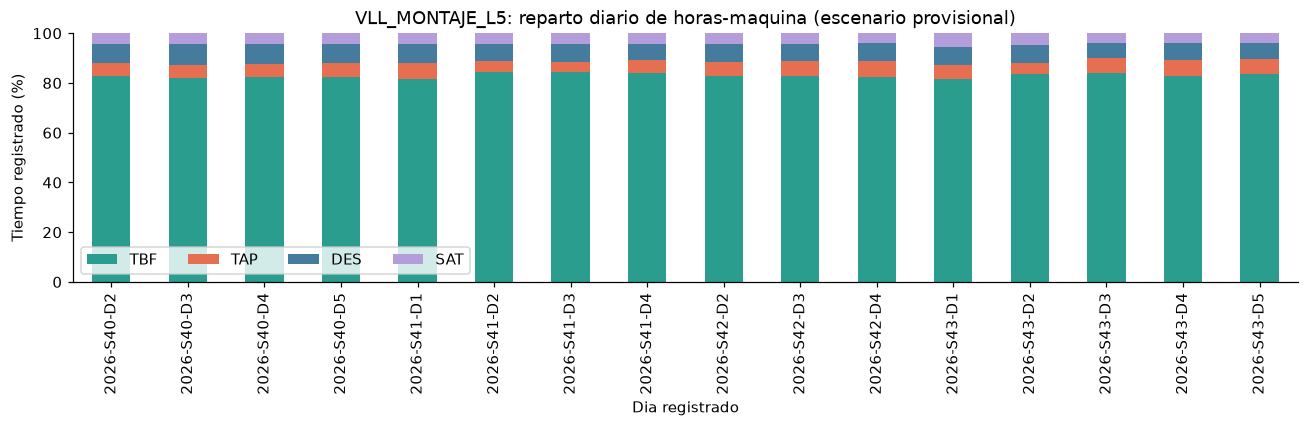

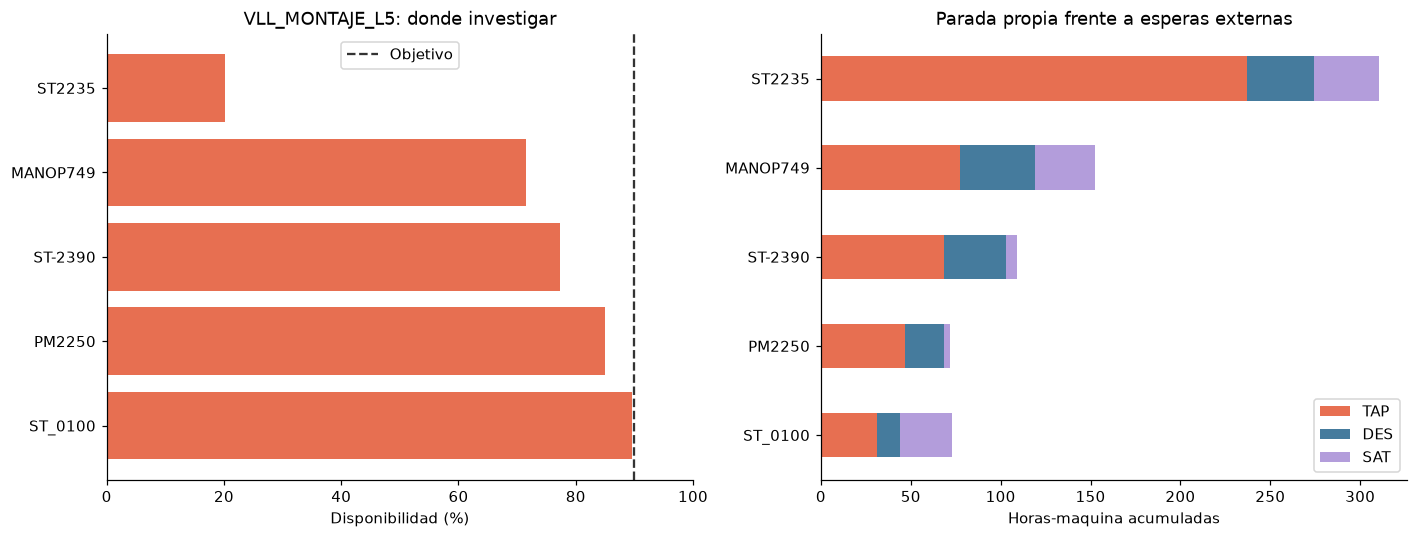

In [8]:
# Cada linea se compara por separado; la ordenacion no se usa como conexion causal.
for line, line_data in working.groupby('Linea'):
    daily = line_data.groupby(['Year', 'Week', 'Jour'])[TIMES].sum()
    shares = daily.div(daily.sum(axis=1).where(lambda s: s.gt(0)), axis=0) * 100
    shares.index = [f'{year}-S{week}-D{day}' for year, week, day in shares.index]
    ax = shares.plot.bar(stacked=True, color=[COLORS[c] for c in TIMES], figsize=(12, 4))
    ax.set(title=f'{line}: reparto diario de horas-maquina (escenario provisional)',
           xlabel='Dia registrado', ylabel='Tiempo registrado (%)', ylim=(0, 100))
    ax.legend(ncol=4)
    plt.tight_layout()
    plt.show()
    # Son horas-maquina; no horas perdidas de produccion final ni piezas de linea.
    top = priorities.loc[priorities.Linea.eq(line)].head(TOP_N).sort_values('availability_pct', ascending=False)
    if not top.empty:
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        axes[0].barh(top.Operacion, top.availability_pct, color=COLORS['TAP'])
        axes[0].axvline(AVAILABILITY_TARGET, color='#333333', linestyle='--', label='Objetivo')
        axes[0].set(xlim=(0, 100), xlabel='Disponibilidad (%)', title=f'{line}: donde investigar')
        axes[0].legend()
        top.set_index('Operacion')[['TAP', 'DES', 'SAT']].plot.barh(stacked=True, ax=axes[1], color=[COLORS[c] for c in ['TAP', 'DES', 'SAT']])
        axes[1].set(xlabel='Horas-maquina acumuladas', ylabel='', title='Parada propia frente a esperas externas')
        plt.tight_layout()
        plt.show()

## 5. Recurrencia y posibles interrupciones breves

La recurrencia se compara en las semanas con datos, usando el escenario sin cierres
sospechosos. Una semana con menos dias no se compara mediante horas absolutas sin
mostrar la exposicion. El mapa usa disponibilidad, e indica dias observados / esperados.

Las microparadas solo se pueden confirmar con eventos y duraciones individuales.
Usamos frecuencia alta (cuartil superior de cada linea) y media menor al umbral
configurado como senal exploratoria. Si TAP y NAP son incompatibles, no calculamos
esa media. Una media baja puede ocultar una mezcla de averias largas y paradas cortas.

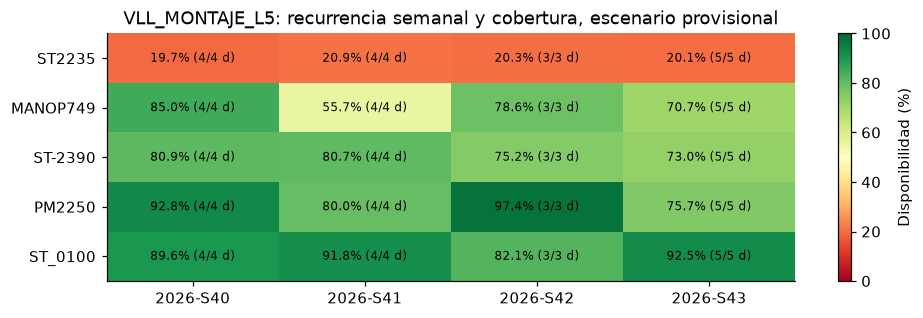

,Linea,Operacion,NAP,TAP,own_stop_rate,mean_stop_seconds
0,VLL_MONTAJE_L5,MANOP749,8376,77.28,571.31,33.21
10,VLL_MONTAJE_L5,PM2110,1817,4.22,76.07,8.36
11,VLL_MONTAJE_L5,PM2120,2644,16.66,108.60,22.68
13,VLL_MONTAJE_L5,PM2140,2126,5.10,86.81,8.64
15,VLL_MONTAJE_L5,PM2180,2357,3.75,96.23,5.73
19,VLL_MONTAJE_L5,PM2240,1401,5.27,56.97,13.54
23,VLL_MONTAJE_L5,PM_0090,5252,10.68,211.31,7.32
24,VLL_MONTAJE_L5,PM_0110,4130,8.80,166.65,7.67
26,VLL_MONTAJE_L5,PM_2260,2639,5.01,107.32,6.83
44,VLL_MONTAJE_L5,ST-0830,1613,4.57,65.94,10.20


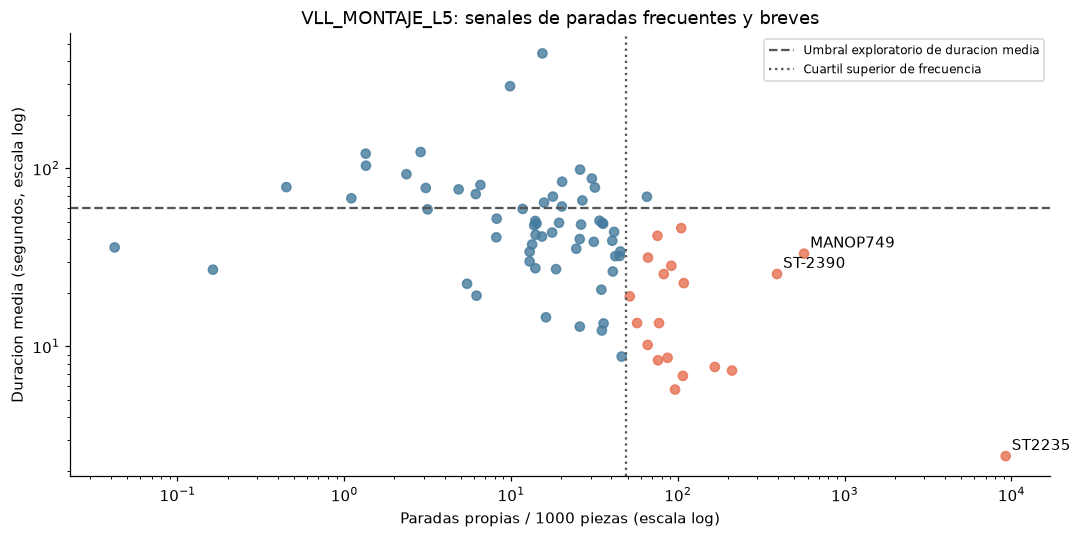

In [9]:
week_expected = working[DAY_KEYS].drop_duplicates().groupby(['Linea', 'Year', 'Week']).size().rename('expected_week_days').reset_index()
if weekly.empty:
    weekly['expected_week_days'] = pd.Series(dtype='int64')
else:
    weekly = weekly.merge(week_expected, on=['Linea', 'Year', 'Week'], validate='many_to_one')
for line, selected in priorities.groupby('Linea'):
    labels = selected.head(TOP_N).Operacion.tolist()
    selected_weekly = weekly.loc[weekly.Linea.eq(line) & weekly.Operacion.isin(labels)]
    heat = selected_weekly.pivot(index='Operacion', columns=['Year', 'Week'], values='availability_pct').reindex(labels)
    if heat.empty:
        continue
    fig, ax = plt.subplots(figsize=(9, max(3, len(heat)*0.55)))
    image = ax.imshow(heat.to_numpy(dtype=float), cmap='RdYlGn', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(len(heat.columns)), [f'{year}-S{week}' for year, week in heat.columns])
    ax.set_yticks(range(len(heat)), heat.index)
    for i, operation in enumerate(heat.index):
        for j, (year, week) in enumerate(heat.columns):
            row = selected_weekly.loc[selected_weekly.Operacion.eq(operation) & selected_weekly.Year.eq(year) & selected_weekly.Week.eq(week)]
            value = heat.iloc[i, j]
            text = 'Sin datos'
            if not row.empty and pd.notna(value):
                r = row.iloc[0]
                text = f'{value:.1f}% ({int(r.observed_days)}/{int(r.expected_week_days)} d)'
            ax.text(j, i, text, ha='center', va='center', fontsize=8)
    ax.set_title(f'{line}: recurrencia semanal y cobertura, escenario provisional')
    fig.colorbar(image, ax=ax, label='Disponibilidad (%)')
    plt.tight_layout()
    plt.show()

stop_candidates = active.loc[active.NAP.gt(0) & active.mean_stop_seconds.gt(0)].copy()
stop_candidates['frequency_threshold'] = stop_candidates.groupby('Linea').own_stop_rate.transform(lambda s: s.quantile(0.75))
stop_candidates['short_frequent_signal'] = stop_candidates.own_stop_rate.ge(stop_candidates.frequency_threshold) & stop_candidates.mean_stop_seconds.lt(MICROSTOP_MEAN_SECONDS)
display(stop_candidates.loc[stop_candidates.short_frequent_signal, ['Linea', 'Operacion', 'NAP', 'TAP', 'own_stop_rate', 'mean_stop_seconds']].round(2))
for line, points in stop_candidates.groupby('Linea'):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.scatter(points.own_stop_rate, points.mean_stop_seconds,
               c=np.where(points.short_frequent_signal, COLORS['TAP'], COLORS['DES']), alpha=0.8)
    ax.axhline(MICROSTOP_MEAN_SECONDS, linestyle='--', color='#555555', label='Umbral exploratorio de duracion media')
    ax.axvline(points.frequency_threshold.iloc[0], linestyle=':', color='#555555', label='Cuartil superior de frecuencia')
    for row in points.nlargest(3, 'own_stop_rate').itertuples():
        ax.annotate(row.Operacion, (row.own_stop_rate, row.mean_stop_seconds), xytext=(4, 4), textcoords='offset points')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set(title=f'{line}: senales de paradas frecuentes y breves',
           xlabel=f'Paradas propias / {STOP_RATE_BASE} piezas (escala log)',
           ylabel='Duracion media (segundos, escala log)')
    ax.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

## 6. Auditoria de las 22 horas: cada dia y cada operacion

La referencia nominal se contrasta con **TBF + TAP + DES + SAT**. No basta con que
la media de la linea se acerque a 22: los excesos y defectos pueden compensarse.
Se muestra el detalle completo operacion-dia, incluidos los dias sin actividad.
Una celda ausente sigue siendo un registro ausente, no un cero.

Se vuelve al texto del CSV y se usa `Decimal` para sumar sin errores de coma flotante.
Distinguimos igualdad exacta, una banda compatible con redondeo bajo una hipotesis
explicita y la tolerancia exploratoria de 0,10 h (6 minutos). Ninguna tolerancia
corrige los datos ni demuestra cual debia ser su jornada real.

In [10]:
from decimal import Decimal

clock_source = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False, **CSV_OPTIONS)
clock_source = clock_source.rename(columns=lambda col: col.strip()).rename(columns=COLUMN_MAP)
clock_source['Source_Row'] = np.arange(2, len(clock_source) + 2)
for col in JOIN_KEYS:
    clock_source[col] = clock_source[col].astype('string').str.strip()
for col in ['Year', 'Week', 'Jour']:
    clock_source[col] = pd.to_numeric(clock_source[col], errors='coerce')
# Solo claves que la validacion previa ha considerado utilizables.
clock_source = clock_source.merge(clean[ROW_KEYS].drop_duplicates(), on=ROW_KEYS,
                                   how='inner', validate='many_to_one').drop_duplicates(ROW_KEYS)
input_per_hour = {'hours': Decimal('1'), 'minutes': Decimal('60'), 'seconds': Decimal('3600')}[TIME_UNIT]
decimal_mark = CSV_OPTIONS.get('decimal', '.')
clock_decimals = clock_source[TIMES].map(lambda value: Decimal(str(value).strip().replace(decimal_mark, '.')))
source_precision = max((max(0, -value.as_tuple().exponent)
                        for col in TIMES for value in clock_decimals[col]), default=2)
source_quantum = Decimal(1).scaleb(-source_precision)
# Condicional: cuatro valores redondeados al mas cercano, cada uno con error <= media unidad.
rounding_bound_input = len(TIMES) * source_quantum / 2
rounding_bound_hours = float(rounding_bound_input / input_per_hour)
nominal_input = Decimal(str(REFERENCE_HOURS)) * input_per_hour
six_minute_input = Decimal(str(TIME_TOLERANCE_HOURS)) * input_per_hour
clock_source['total_input_decimal'] = clock_decimals.apply(lambda row: sum(row, Decimal(0)), axis=1)
clock_source['gap_input_decimal'] = clock_source.total_input_decimal.map(lambda value: value - nominal_input)
clock_source['total_hours_exact'] = clock_source.total_input_decimal.map(lambda value: float(value / input_per_hour))
clock_source['gap_hours'] = clock_source.gap_input_decimal.map(lambda value: float(value / input_per_hour))
clock_source['gap_minutes'] = 60 * clock_source.gap_hours
clock_source['exact_reference'] = clock_source.gap_input_decimal.eq(0)
clock_source['under_reference'] = clock_source.gap_input_decimal.lt(0)
clock_source['over_reference'] = clock_source.gap_input_decimal.gt(0)
clock_source['within_rounding'] = clock_source.gap_input_decimal.map(lambda value: abs(value) <= rounding_bound_input)
clock_source['within_six_minutes'] = clock_source.gap_input_decimal.map(lambda value: abs(value) <= six_minute_input)
clock_source['zero_total'] = clock_source.total_input_decimal.eq(0)
clock_columns = ['Source_Row'] + ROW_KEYS + ['total_hours_exact', 'gap_hours', 'gap_minutes',
    'exact_reference', 'under_reference', 'over_reference', 'within_rounding', 'within_six_minutes', 'zero_total']
clock_audit = clock_source[clock_columns].merge(records, on=ROW_KEYS, how='left', validate='one_to_one')
clock_counts = pd.Series({
    'Registros auditados': len(clock_audit),
    'Exactamente la referencia': int(clock_audit.exact_reference.sum()),
    'Por debajo': int(clock_audit.under_reference.sum()),
    'Por encima': int(clock_audit.over_reference.sum()),
    'Total de tiempos igual a cero': int(clock_audit.zero_total.sum()),
    'Fuera de la banda de redondeo condicional': int((~clock_audit.within_rounding).sum()),
    'Fuera de la tolerancia exploratoria de 6 min': int((~clock_audit.within_six_minutes).sum()),
}, name='Registros')
display(clock_counts.to_frame())
print(f'Precision visible maxima: {source_precision} decimales en la unidad de entrada.')
print(f'Si los cuatro tiempos se redondean al mas cercano, la suma puede desviarse hasta '
      f'{rounding_bound_hours:.4f} h ({60 * rounding_bound_hours:.2f} min) solo por redondeo.')
print('Este limite supone redondeo independiente; no confirma la precision interna del sistema.')
# Comparar la comprobacion binaria antigua con la suma decimal exacta.
float_outside = clock_audit[TIMES].sum(axis=1).sub(REFERENCE_HOURS).abs().gt(TIME_TOLERANCE_HOURS)
clock_boundary_cases = clock_audit.loc[float_outside.ne(~clock_audit.within_six_minutes),
                                     ['Source_Row'] + ROW_KEYS + ['total_hours_exact', 'gap_minutes']]
print('Casos cuya marca cambia al evitar el error numerico en el limite de la tolerancia:')
display(clock_boundary_cases)

clock_tolerance_sensitivity=[]
for label,band_input in [("Igualdad exacta",Decimal(0)), ("Redondeo al mas cercano: limite condicional",rounding_bound_input), ("Truncado de cuatro campos: limite condicional",2*rounding_bound_input), ("Tolerancia exploratoria anterior",six_minute_input)]:
    within=clock_source.gap_input_decimal.map(lambda value:abs(value)<=band_input)
    clock_tolerance_sensitivity.append({"Supuesto":label,"Banda_minutos":float(band_input/input_per_hour)*60,"Dentro":int(within.sum()),"Fuera":int((~within).sum())})
display(pd.DataFrame(clock_tolerance_sensitivity))
assert clock_audit.exact_reference.sum()+clock_audit.under_reference.sum()+clock_audit.over_reference.sum()==len(clock_audit)
assert not clock_audit.duplicated(ROW_KEYS).any()


,Registros
Registros auditados,1820
Exactamente la referencia,512
Por debajo,1075
Por encima,233
Total de tiempos igual a cero,16
Fuera de la banda de redondeo condicional,1098
Fuera de la tolerancia exploratoria de 6 min,1030


Precision visible maxima: 2 decimales en la unidad de entrada.
Si los cuatro tiempos se redondean al mas cercano, la suma puede desviarse hasta 0.0200 h (1.20 min) solo por redondeo.
Este limite supone redondeo independiente; no confirma la precision interna del sistema.
Casos cuya marca cambia al evitar el error numerico en el limite de la tolerancia:


,Source_Row,Linea,Year,Week,Jour,Operacion,total_hours_exact,gap_minutes
271,273,VLL_MONTAJE_L5,2026,40,3,ST_3100,22.1,6.0
628,630,VLL_MONTAJE_L5,2026,41,2,ST_0140,21.9,-6.0
789,791,VLL_MONTAJE_L5,2026,41,4,ST-2225,21.9,-6.0
1273,1275,VLL_MONTAJE_L5,2026,42,4,ST_3300,21.9,-6.0
1520,1522,VLL_MONTAJE_L5,2026,43,2,ST-2375,21.9,-6.0


,Supuesto,Banda_minutos,Dentro,Fuera
0,Igualdad exacta,0.0,512,1308
1,Redondeo al mas cercano: limite condicional,1.2,722,1098
2,Truncado de cuatro campos: limite condicional,2.4,752,1068
3,Tolerancia exploratoria anterior,6.0,790,1030


In [11]:
# Todas las combinaciones esperadas de operaciones configuradas y jornadas observadas.
clock_days = observed_raw_days.copy()
if calendar is not None:
    clock_days = pd.concat([clock_days, calendar[DAY_KEYS]], ignore_index=True).drop_duplicates()
clock_grid = config.merge(clock_days, on='Linea', how='inner', validate='many_to_many')
clock_grid = clock_grid.merge(clock_audit[['Source_Row'] + ROW_KEYS + [
    'total_hours_exact', 'gap_hours', 'exact_reference', 'under_reference', 'over_reference',
    'within_rounding', 'within_six_minutes', 'zero_total']], on=ROW_KEYS, how='left', validate='one_to_one')
clock_grid['has_clock_record'] = clock_grid.total_hours_exact.notna()
clock_by_day = clock_grid.groupby(DAY_KEYS).agg(
    operaciones_esperadas=('Operacion', 'size'), registros_utilizables=('has_clock_record', 'sum'),
    exactamente_referencia=('exact_reference', lambda s: s.eq(True).sum()),
    por_debajo=('under_reference', lambda s: s.eq(True).sum()),
    por_encima=('over_reference', lambda s: s.eq(True).sum()),
    tiempos_cero=('zero_total', lambda s: s.eq(True).sum()),
    minimo_h=('total_hours_exact', 'min'), mediana_h=('total_hours_exact', 'median'),
    maximo_h=('total_hours_exact', 'max'))
clock_by_day['registros_ausentes_o_apartados'] = clock_by_day.operaciones_esperadas - clock_by_day.registros_utilizables
clock_by_operation = clock_grid.groupby(JOIN_KEYS).agg(
    dias_esperados=('Jour', 'size'), dias_con_datos=('has_clock_record', 'sum'),
    dias_exactos=('exact_reference', lambda s: s.eq(True).sum()),
    dias_bajo_referencia=('under_reference', lambda s: s.eq(True).sum()),
    dias_sobre_referencia=('over_reference', lambda s: s.eq(True).sum()),
    dias_tiempo_cero=('zero_total', lambda s: s.eq(True).sum()),
    media_desvio_h=('gap_hours', 'mean'), minimo_h=('total_hours_exact', 'min'),
    maximo_h=('total_hours_exact', 'max'))
clock_by_operation['todos_los_dias_exactos'] = clock_by_operation.dias_exactos.eq(clock_by_operation.dias_esperados)
print('Balance de TODAS las operaciones por dia:')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(clock_by_day.round(3))
print('Operaciones que cumplen exactamente la referencia todos los dias:')
display(clock_by_operation.loc[clock_by_operation.todos_los_dias_exactos])
print('Resumen de TODAS las operaciones:')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(clock_by_operation.round(3))
clock_matrix = clock_grid.pivot(index=JOIN_KEYS + ['Orden_OP'], columns=['Year', 'Week', 'Jour'], values='total_hours_exact').sort_index(level=['Linea', 'Orden_OP'])
print('Matriz completa: cada celda contiene horas, NaN significa ausencia de registro utilizable.')
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(clock_matrix.round(2))

Balance de TODAS las operaciones por dia:


operaciones_esperadas  registros_utilizables  \
Linea          Year Week Jour                                                 
VLL_MONTAJE_L5 2026 40   1                        91                     91   
                         2                        91                     91   
                         3                        91                     91   
                         4                        91                     91   
                         5                        91                     91   
                    41   1                        91                     91   
                         2                        91                     91   
                         3                        91                     91   
                         4                        91                     91   
                         5                        91                     91   
                    42   1                        91                     91   
                         2                        91                     91   
                         3                        91                     91   
                         4                        91                     91   
                         5                        91                     91   
                    43   1                        91                     91   
                         2                        91                     91   
                         3                        91                     91   
                         4                        91                     91   
                         5                        91                     91   

                               exactamente_referencia  por_debajo  por_encima  \
Linea          Year Week Jour                                                   
VLL_MONTAJE_L5 2026 40   1                         91           0           0   
                         2                          9          68          14   
                         3                         11          66          14   
                         4                          9          64          18   
                         5                          9          64          18   
                    41   1                          9          66          16   
                         2                          0          83           8   
                         3                          8          69          14   
                         4                         14          64          13   
                         5                         91           0           0   
                    42   1                         91           0           0   
                         2                         12          70           9   
                         3                         10          67          14   
                         4                         12          65          14   
                         5                         91           0           0   
                    43   1                          9          66          16   
                         2                          7          65          19   
                         3                         10          66          15   
                         4                          7          67          17   
                         5                         12          65          14   

                               tiempos_cero  minimo_h  mediana_h  maximo_h  \
Linea          Year Week Jour                                                
VLL_MONTAJE_L5 2026 40   1                0      22.0      22.00     22.00   
                         2                1       0.0      21.74     23.79   
                         3                1       0.0      21.64     23.68   
                         4                1       0.0      21.70     23.93   
                         5               

Operaciones que cumplen exactamente la referencia todos los dias:


,,dias_esperados,dias_con_datos,dias_exactos,dias_bajo_referencia,dias_sobre_referencia,dias_tiempo_cero,media_desvio_h,minimo_h,maximo_h,todos_los_dias_exactos
Linea,Operacion,,,,,,,,,,


Resumen de TODAS las operaciones:


dias_esperados  dias_con_datos  dias_exactos  \
Linea          Operacion                                                 
VLL_MONTAJE_L5 MANOP749               20              20             4   
               Ma_BM1_2               20              20            10   
               Ma_BM2_2               20              20            11   
               Ma_VESRE               20              20             9   
               Ma_VES_0               20              20            14   
               ManBM1_1               20              20            14   
               ManBM2_1               20              20             9   
               ManutPul               20              20             8   
               PM-2020                20              20             4   
               PM2087                 20              20             4   
               PM2110                 20              20             4   
               PM2120                 20              20             4   
               PM2130                 20              20            19   
               PM2140                 20              20             4   
               PM2150                 20              20             4   
               PM2180                 20              20             4   
               PM2190                 20              20             4   
               PM2200                 20              20             4   
               PM2230                 20              20             4   
               PM2240                 20              20             4   
               PM2250                 20              20             4   
               PM2290                 20              20             4   
               PM2300                 20              20             4   
               PM_0090                20              20             4   
               PM_0110                20              20             4   
               PM_0350                20              20            12   
               PM_2260                20              20             4   
               PM_2270                20              20             4   
               PM_2310                20              20             4   
               PM_2330                20              20             4   
               ST-0050                20              20             4   
               ST-0120                20              20             4   
               ST-0230                20              20             4   
               ST-0240                20              20            10   
               ST-0250                20              20             4   
               ST-0260                20              20             4   
               ST-0270                20              20             4   
               ST-0295                20              20             9   
               ST-0300                20              20            10   
               ST-0305                20              20             4   
               ST-0340                20              20             4   
               ST-0370                20              20            10   
               ST-0385                20              20             7   
               ST-0410                20              20             4   
               ST-0830                20              20             4   
               ST-0840                20              20             4   
               ST-0850                20              20             4   
               ST-1000                20              20             4   
               ST-2001                20              20             4   
               ST-2002                20              20             5   
               ST-2030                20              20             6   
               ST-2035                20              20             4   
               ST-2040        

Matriz completa: cada celda contiene horas, NaN significa ausencia de registro utilizable.


Year                               2026                                     \
Week                                 40                                 41   
Jour                                  1      2      3      4      5      1   
Linea          Operacion Orden_OP                                            
VLL_MONTAJE_L5 ST_0015   1         22.0  20.20  20.90  20.90  20.58  21.14   
               ST_0020   2         22.0  21.99  21.98  21.98  21.99  21.97   
               ST_0030   3         22.0   0.00   0.00   0.00   0.00   0.00   
               ST_0040   4         22.0  21.99  22.00  22.00  22.01  22.00   
               ST-0050   5         22.0  21.18  21.47  21.15  21.48  21.24   
               PM_0090   6         22.0  23.79  23.68  23.16  22.51  23.87   
               ST_0095   7         22.0  21.99  21.99  21.98  21.98  22.00   
               ST_0100   8         22.0  21.21  21.43  21.21  21.45  21.40   
               PM_0110   9         22.0  23.06  23.58  22.78  22.31  24.42   
               ST_0115   10        22.0  21.83  21.88  21.99  21.68  21.46   
               ST-0120   11        22.0  21.86  21.86  21.69  21.70  21.61   
               ST_0140   12        22.0  21.95  21.98  21.80  21.91  21.75   
               ST_0150   13        22.0  21.84  21.82  21.76  21.74  21.62   
               ST_0160   14        22.0  21.80  21.63  21.85  21.72  21.64   
               ST-0230   15        22.0  20.79  20.81  20.79  21.08  21.16   
               ST-0240   16        22.0  21.89  21.99  22.00  21.99  22.00   
               ST-0250   17        22.0  20.70  20.80  20.77  20.71  21.11   
               ST0261    18        22.0  21.37  21.11  21.04  20.61  20.32   
               ST0259    19        22.0  21.98  22.00  22.01  21.99  22.00   
               ST-0260   20        22.0  17.99  17.93  17.83  17.65  18.36   
               ST_0265   21        22.0  21.98  22.00  22.00  22.00  22.00   
               ST-0270   22        22.0  21.03  20.91  21.02  20.89  20.98   
               ST0280    23        22.0  22.32  21.36  22.01  21.08  23.32   
               ST_0290   24        22.0  21.25  21.27  21.31  21.15  21.39   
               ST-0295   25        22.0  22.00  22.00  21.97  22.00  21.99   
               ST-0300   26        22.0  22.00  21.99  22.00  22.00  21.99   
               ST-0305   27        22.0  20.70  20.83  21.45  21.82  21.71   
               ST-0340   28        22.0  21.50  21.59  21.51  21.45  21.71   
               PM_0350   29        22.0  22.00  22.00  22.00  22.00  21.99   
               ST-0370   30        22.0  21.99  22.01  22.00  22.00  21.99   
               ST-0385   31        22.0  21.71  21.95  21.89  21.68  22.00   
               ST-0410   32        22.0  21.98  21.98  21.95  22.10  21.99   
               ST-1000   33        22.0  19.91  19.06  19.08  19.47  18.61   
               ManutPul  34        22.0  22.00  22.01  21.99  22.01  21.99   
               ST-2002   35        22.0  21.97  21.98  21.99  21.98  21.97   
               ST-2001   36        22.0  21.21  20.99  21.43  21.41  21.44   
               PM-2020   37        22.0  21.30  20.84  20.89  20.81  20.80   
               ST-2030   38        22.0  21.96  21.94  21.95  21.93  21.96   
               ST-2035   39        22.0  21.68  21.72  21.84  21.77  21.89   
               ST-2040   40        22.0  21.36  21.63  21.60  21.67  21.37   
               ST-2050   41        22.0  21.42  21.64  21.70  21.49  21.42   
               ST-2070   42        22.0  19.76  21.39  21.33  21.47  21.59   
               PM2087    43        22.0  21.46  21.16  20.43  21.11  21.50   
               ST-2090   44        22.0  21.59  21.51  21.57  21.36  21.65   
               ST-2096   45        22.0  22.01  21.99  22.00  22.02  22.01   
               ST-2100   46        22.0  21.98  21.97  21.99  21.98  21.97   
               PM2110    47        22.0  21.40  21.52  21.60  21.79  21.58   
               PM2120 

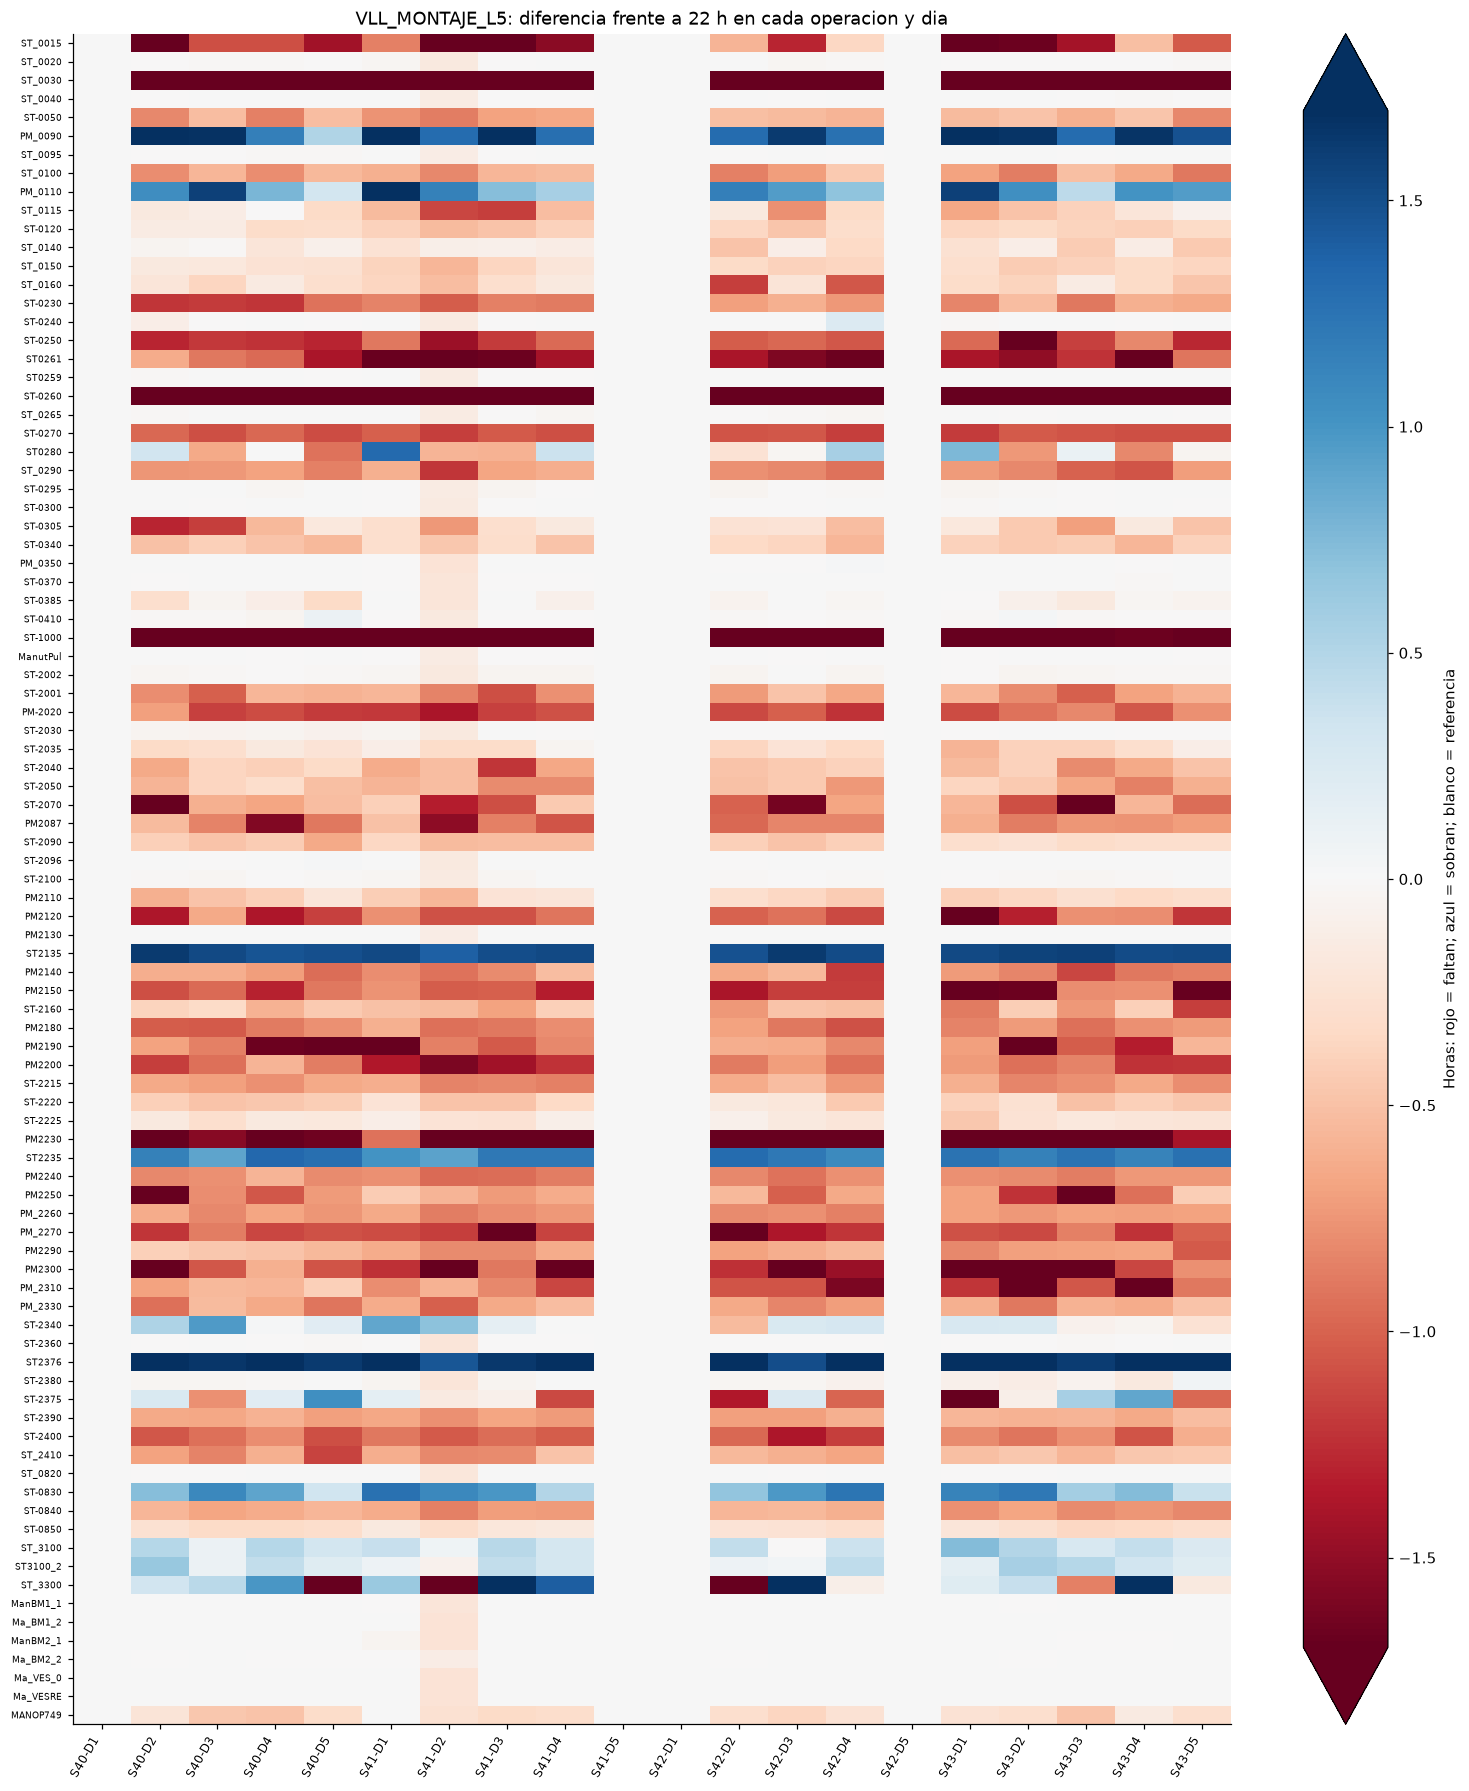

Color saturado a +/-1.70 h; los valores reales permanecen en la matriz, incluidos ceros y extremos.


In [12]:
from matplotlib.colors import TwoSlopeNorm
# Los colores se saturan para que los pequenos desvios no queden ocultos por los ceros.
for line in clock_grid.Linea.unique():
    line_grid = clock_grid.loc[clock_grid.Linea.eq(line)]
    gap_matrix = line_grid.pivot(index=['Operacion', 'Orden_OP'], columns=['Year', 'Week', 'Jour'], values='gap_hours').sort_index(level='Orden_OP')
    finite = line_grid.loc[line_grid.total_hours_exact.gt(0), 'gap_hours'].abs().dropna()
    limit = max(0.1, float(finite.quantile(0.95))) if len(finite) else 1.0
    fig, ax = plt.subplots(figsize=(14, max(4, len(gap_matrix) * 0.18)))
    cmap = plt.get_cmap('RdBu').copy()
    cmap.set_bad('#d5dae2')
    image = ax.imshow(np.ma.masked_invalid(gap_matrix.to_numpy(dtype=float)), aspect='auto', cmap=cmap,
                      norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit))
    ax.set_yticks(range(len(gap_matrix)), gap_matrix.index.get_level_values('Operacion'), fontsize=6)
    ax.set_xticks(range(len(gap_matrix.columns)), [f'S{w}-D{day}' for year,w,day in gap_matrix.columns], rotation=60, ha='right', fontsize=8)
    ax.set_title(f'{line}: diferencia frente a {REFERENCE_HOURS:g} h en cada operacion y dia')
    fig.colorbar(image, ax=ax, label='Horas: rojo = faltan; azul = sobran; blanco = referencia', extend='both')
    plt.tight_layout()
    plt.show()
    print(f'Color saturado a +/-{limit:.2f} h; los valores reales permanecen en la matriz, incluidos ceros y extremos.')

### 6.1 Buscar explicaciones: patron comun, sesgo por operacion y registros nulos

- Un total de cero significa que las cuatro categorias no aportan tiempo; no demuestra
  una averia de 22 horas ni que ese tiempo sea recuperable.
- Un deficit persistente de una operacion puede ser una categoria omitida, una jornada
  requerida diferente o un problema de captura; requiere contrastar el contrato del dato.
- Un exceso no se explica por tiempo que falta. Si la jornada es realmente de 22 horas y
  los estados son excluyentes, hay que revisar solapes, ventanas de acumulacion o unidades.
- Desvios de varias horas no se justifican solo con redondear cuatro numeros a dos decimales.
- Los cuatro dias sin actividad con 22 h de TAP en todas las operaciones pueden representar
  una asignacion administrativa. Que sumen exactamente 22 no certifica su significado.

Sesgos negativos y positivos en jornadas con alguna actividad en la linea:


dias  media_desvio_h  minimo_desvio_h  \
Linea          Operacion                                          
VLL_MONTAJE_L5 ST_0030      16         -22.000           -22.00   
               ST-0260      16          -3.764            -4.35   
               ST-1000      16          -2.622            -3.41   
               PM2230       16          -2.491            -4.43   
               PM2300       16          -1.499            -2.49   
               ST0261       16          -1.379            -1.92   
               ST_0015      16          -1.288            -2.02   
               PM_2270      16          -1.269            -2.73   

                          maximo_desvio_h  fuera_6min  tiempos_cero  \
Linea          Operacion                                              
VLL_MONTAJE_L5 ST_0030             -22.00          16            16   
               ST-0260              -3.28          16             0   
               ST-1000              -1.67          16             0   
               PM2230               -0.92          16             0   
               PM2300               -0.60          16             0   
               ST0261               -0.63          16             0   
               ST_0015              -0.35          16             0   
               PM_2270              -0.86          16             0   

                          rango_desvio_h  
Linea          Operacion                  
VLL_MONTAJE_L5 ST_0030              0.00  
               ST-0260              1.07  
               ST-1000              1.74  
               PM2230               3.51  
               PM2300               1.89  
               ST0261               1.29  
               ST_0015              1.67  
               PM_2270              1.87

dias  media_desvio_h  minimo_desvio_h  \
Linea          Operacion                                          
VLL_MONTAJE_L5 ST2376       16           1.787             1.45   
               ST2135       16           1.528             1.39   
               PM_0090      16           1.469             0.51   
               ST2235       16           1.166             0.89   
               PM_0110      16           1.026             0.31   
               ST-0830      16           0.864             0.34   
               ST_3100      16           0.346            -0.01   
               ST3100_2     16           0.277            -0.07   

                          maximo_desvio_h  fuera_6min  tiempos_cero  \
Linea          Operacion                                              
VLL_MONTAJE_L5 ST2376                2.21          16             0   
               ST2135                1.63          16             0   
               PM_0090               1.87          16             0   
               ST2235                1.33          16             0   
               PM_0110               2.42          16             0   
               ST-0830               1.27          16             0   
               ST_3100               0.74          13             0   
               ST3100_2              0.65          11             0   

                          rango_desvio_h  
Linea          Operacion                  
VLL_MONTAJE_L5 ST2376               0.76  
               ST2135               0.24  
               PM_0090              1.36  
               ST2235               0.44  
               PM_0110              2.11  
               ST-0830              0.93  
               ST_3100              0.75  
               ST3100_2             0.72

Mayores defectos (sin mezclar filas con todas las categorias a cero):


,Source_Row,Linea,Year,Week,Jour,Operacion,TBF,TAP,DES,SAT,total_hours_exact,gap_hours,NAP,NPR
363,456,VLL_MONTAJE_L5,2026,40,5,ST_3300,9.62,0.05,7.21,0.00,16.88,-5.12,9,2165
746,1021,VLL_MONTAJE_L5,2026,42,2,PM2230,16.23,0.32,1.02,0.00,17.57,-4.43,25,1526
308,401,VLL_MONTAJE_L5,2026,40,5,ST-0260,14.46,1.14,1.87,0.18,17.65,-4.35,83,1516
217,310,VLL_MONTAJE_L5,2026,40,4,ST-0260,14.80,0.82,2.09,0.12,17.83,-4.17,81,1497
672,765,VLL_MONTAJE_L5,2026,41,4,ST-0260,15.85,0.48,1.32,0.20,17.85,-4.15,55,1578
126,219,VLL_MONTAJE_L5,2026,40,3,ST-0260,14.81,0.71,2.33,0.08,17.93,-4.07,80,1529
35,128,VLL_MONTAJE_L5,2026,40,2,ST-0260,14.72,0.97,2.24,0.06,17.99,-4.01,75,1526
1110,1476,VLL_MONTAJE_L5,2026,43,2,PM2230,16.74,0.09,1.03,0.22,18.08,-3.92,14,1524
854,1129,VLL_MONTAJE_L5,2026,42,3,ST-0260,15.30,0.53,2.08,0.30,18.21,-3.79,55,1541
1036,1402,VLL_MONTAJE_L5,2026,43,1,ST-0260,14.93,0.61,1.66,1.03,18.23,-3.77,52,1502


Mayores excesos:


,Source_Row,Linea,Year,Week,Jour,Operacion,TBF,TAP,DES,SAT,total_hours_exact,gap_hours,NAP,NPR
909,1184,VLL_MONTAJE_L5,2026,42,3,ST_3300,18.72,0.04,7.68,0.00,26.44,4.44,12,2369
636,729,VLL_MONTAJE_L5,2026,41,3,ST_3300,18.04,0.03,8.23,0.00,26.30,4.30,8,2481
388,481,VLL_MONTAJE_L5,2026,41,1,PM_0110,21.28,1.07,1.28,0.79,24.42,2.42,427,1541
710,803,VLL_MONTAJE_L5,2026,41,4,ST2376,22.78,0.52,0.70,0.21,24.21,2.21,45,772
1364,1730,VLL_MONTAJE_L5,2026,43,4,ST_3300,16.92,0.11,7.12,0.00,24.15,2.15,24,2972
1074,1440,VLL_MONTAJE_L5,2026,43,1,ST2376,21.77,1.42,0.22,0.67,24.08,2.08,116,749
983,1258,VLL_MONTAJE_L5,2026,42,4,ST2376,22.44,0.68,0.46,0.42,24.00,2.00,48,777
1347,1713,VLL_MONTAJE_L5,2026,43,4,ST2376,22.24,1.00,0.40,0.35,23.99,1.99,104,770
255,348,VLL_MONTAJE_L5,2026,40,4,ST2376,22.05,0.30,1.11,0.47,23.93,1.93,34,552
1165,1531,VLL_MONTAJE_L5,2026,43,2,ST2376,22.61,0.60,0.36,0.31,23.88,1.88,70,766


Registros sin ningun tiempo asignado:


,Source_Row,Linea,Year,Week,Jour,Operacion,TBF,TAP,DES,SAT,total_hours_exact,gap_hours,NAP,NPR
168,170,VLL_MONTAJE_L5,2026,40,2,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0
259,261,VLL_MONTAJE_L5,2026,40,3,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0
350,352,VLL_MONTAJE_L5,2026,40,4,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0
441,443,VLL_MONTAJE_L5,2026,40,5,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0
532,534,VLL_MONTAJE_L5,2026,41,1,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0
623,625,VLL_MONTAJE_L5,2026,41,2,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0
714,716,VLL_MONTAJE_L5,2026,41,3,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0
805,807,VLL_MONTAJE_L5,2026,41,4,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0
1078,1080,VLL_MONTAJE_L5,2026,42,2,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0
1169,1171,VLL_MONTAJE_L5,2026,42,3,ST_0030,0.0,0.0,0.0,0.0,0.0,-22.0,0,0


Registros en los que TBF por si solo supera la referencia nominal:


,Source_Row,Linea,Year,Week,Jour,Operacion,TBF,TAP,DES,SAT,total_hours_exact,gap_hours,NAP,NPR
185,187,VLL_MONTAJE_L5,2026,40,3,Ma_VESRE,22.01,0.00,0.00,0.00,22.01,0.01,0,0
226,228,VLL_MONTAJE_L5,2026,40,3,ST-0830,22.04,0.22,0.00,0.83,23.09,1.09,107,1503
276,278,VLL_MONTAJE_L5,2026,40,4,Ma_VESRE,22.01,0.00,0.00,0.00,22.01,0.01,0,0
346,348,VLL_MONTAJE_L5,2026,40,4,ST2376,22.05,0.30,1.11,0.47,23.93,1.93,34,552
365,367,VLL_MONTAJE_L5,2026,40,5,Ma_BM1_2,22.01,0.00,0.00,0.00,22.01,0.01,0,0
367,369,VLL_MONTAJE_L5,2026,40,5,Ma_VESRE,22.01,0.00,0.00,0.00,22.01,0.01,0,0
456,458,VLL_MONTAJE_L5,2026,41,1,Ma_BM1_2,22.01,0.00,0.00,0.00,22.01,0.01,0,0
459,461,VLL_MONTAJE_L5,2026,41,1,Ma_VES_0,22.01,0.00,0.00,0.00,22.01,0.01,2,0
499,501,VLL_MONTAJE_L5,2026,41,1,ST-0830,22.53,0.14,0.00,0.60,23.27,1.27,82,1539
590,592,VLL_MONTAJE_L5,2026,41,2,ST-0830,22.19,0.27,0.00,0.63,23.09,1.09,96,1546


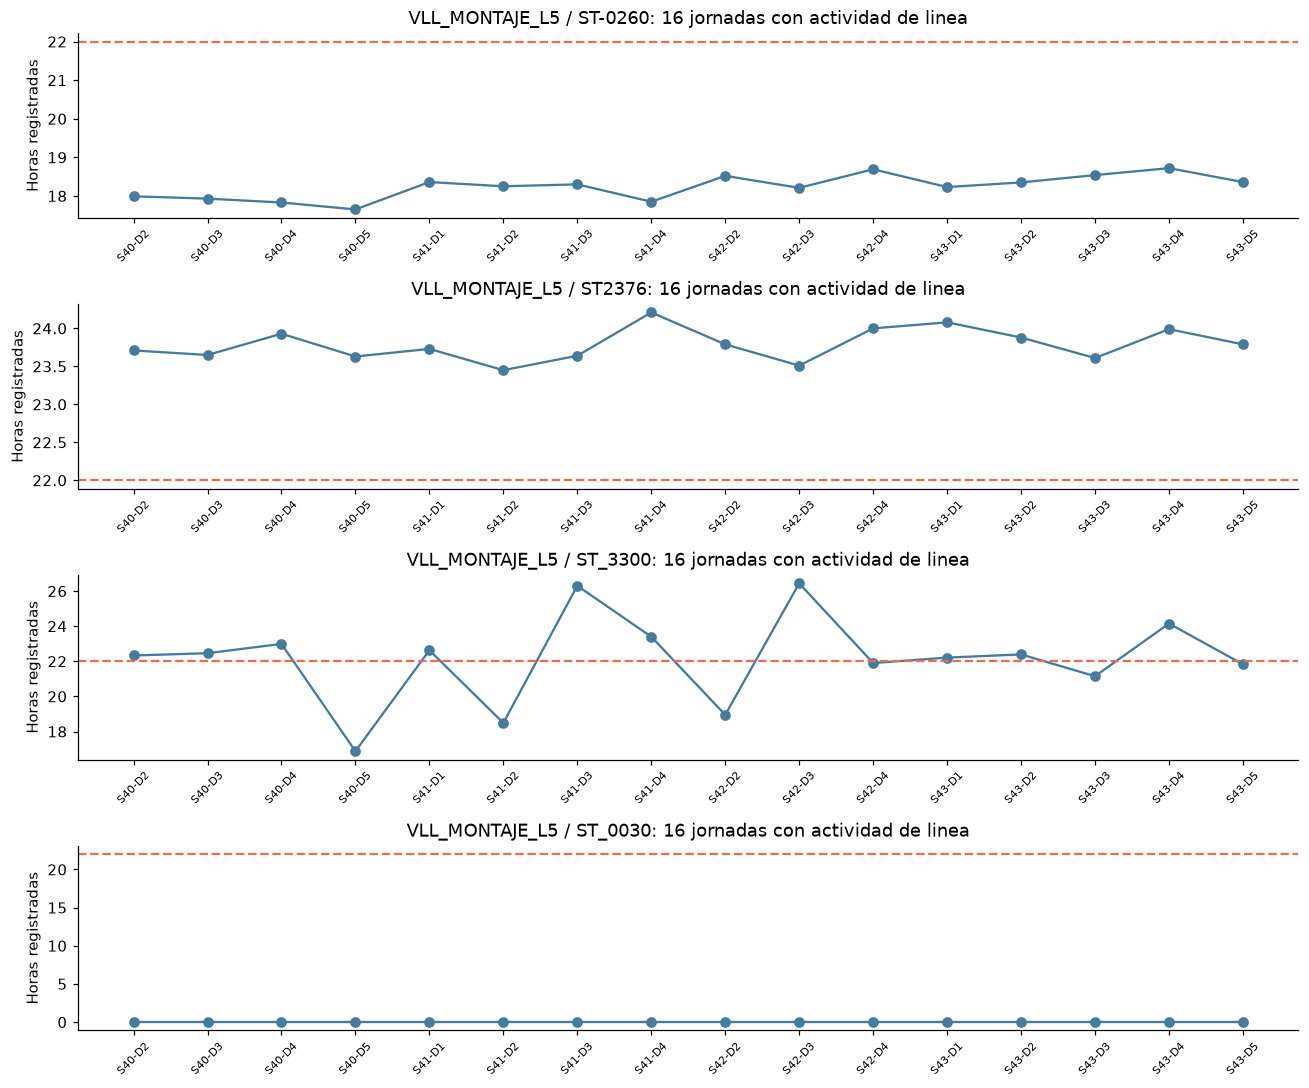

In [13]:
activity_clock = clock_audit.merge(working[ROW_KEYS].drop_duplicates(), on=ROW_KEYS, how='inner', validate='one_to_one')
activity_clock['abs_gap_hours'] = activity_clock.gap_hours.abs()
clock_activity_summary = activity_clock.groupby(JOIN_KEYS).agg(
    dias=('Jour', 'size'), media_desvio_h=('gap_hours', 'mean'),
    minimo_desvio_h=('gap_hours', 'min'), maximo_desvio_h=('gap_hours', 'max'),
    fuera_6min=('within_six_minutes', lambda s: (~s).sum()),
    tiempos_cero=('zero_total', 'sum'))
clock_activity_summary['rango_desvio_h'] = clock_activity_summary.maximo_desvio_h - clock_activity_summary.minimo_desvio_h
print('Sesgos negativos y positivos en jornadas con alguna actividad en la linea:')
display(clock_activity_summary.nsmallest(8, 'media_desvio_h').round(3))
display(clock_activity_summary.nlargest(8, 'media_desvio_h').round(3))
print('Mayores defectos (sin mezclar filas con todas las categorias a cero):')
clock_detail_columns = ['Source_Row'] + ROW_KEYS + TIMES + ['total_hours_exact', 'gap_hours', 'NAP', 'NPR']
display(activity_clock.loc[activity_clock.total_hours_exact.gt(0)].nsmallest(10, 'gap_hours')[clock_detail_columns])
print('Mayores excesos:')
display(activity_clock.nlargest(10, 'gap_hours')[clock_detail_columns])
print('Registros sin ningun tiempo asignado:')
display(clock_audit.loc[clock_audit.zero_total, clock_detail_columns])
print('Registros en los que TBF por si solo supera la referencia nominal:')
display(clock_audit.loc[clock_audit.TBF.gt(REFERENCE_HOURS), clock_detail_columns])
# Ejemplos elegidos por criterio numerico, sin codificar nombres de maquinas.
nonzero_summary = clock_activity_summary.loc[clock_activity_summary.tiempos_cero.eq(0)]
examples = []
if len(nonzero_summary):
    examples += [nonzero_summary.media_desvio_h.idxmin(), nonzero_summary.media_desvio_h.idxmax(), nonzero_summary.rango_desvio_h.idxmax()]
zeros = clock_activity_summary.loc[clock_activity_summary.tiempos_cero.gt(0)]
if len(zeros): examples.append(zeros.tiempos_cero.idxmax())
examples = list(dict.fromkeys(examples))
if examples:
    fig, axes = plt.subplots(len(examples), 1, figsize=(12, 2.5 * len(examples)), squeeze=False)
    for axis, (line, operation) in zip(axes[:,0], examples):
        sample = activity_clock.loc[activity_clock.Linea.eq(line) & activity_clock.Operacion.eq(operation)].sort_values(['Year','Week','Jour'])
        labels = [f'S{w}-D{day}' for w,day in sample[['Week','Jour']].to_numpy()]
        axis.plot(range(len(sample)), sample.total_hours_exact, marker='o', color='#457b9d')
        axis.axhline(REFERENCE_HOURS, color='#e76f51', linestyle='--')
        axis.set_xticks(range(len(sample)), labels, rotation=45, fontsize=7)
        axis.set(title=f'{line} / {operation}: {len(sample)} jornadas con actividad de linea', ylabel='Horas registradas')
    plt.tight_layout()
    plt.show()

### 6.2 Pueden explicar las microparadas las horas que faltan?

**Si estan registradas en TAP, ya forman parte de la suma.** Solo las interrupciones
omitidas del tiempo, una clasificacion incompleta o una ventana distinta podrian dejar
un hueco; los acumulados no permiten demostrarlo. Un exceso de horas exige otra explicacion.

Contrastamos el desvio con NAP, FPM y duracion media, distinguiendo registros con
contadores incompatibles. Las asociaciones son descriptivas: mezclan operaciones,
carga y condiciones distintas y no acreditan una causa. Tambien mostramos deficits
cuando NAP=0: no se pueden atribuir a paradas registradas que no existen en ese contador.

,registros,mediana_desvio_absoluto_h,por_debajo,por_encima,fuera_6min
duration_group,,,,,
Contador/duracion por revisar,11,0.020,9,0,5
Media 1-2 min,215,0.350,170,21,148
Media 2-15 min,58,0.515,41,6,37
Media < 1 min,981,0.580,753,170,775
Media >= 15 min,14,0.010,11,2,6
Sin paradas contadas,74,0.225,65,2,37


,gap_hours,abs_gap_hours,NAP,fpm_clock,mean_stop_minutes_clock
gap_hours,1.000,-0.626,0.086,0.121,0.028
abs_gap_hours,-0.626,1.000,0.163,0.129,-0.225
NAP,0.086,0.163,1.000,0.953,-0.487
fpm_clock,0.121,0.129,0.953,1.000,-0.466
mean_stop_minutes_clock,0.028,-0.225,-0.487,-0.466,1.000


Ejemplos de deficit sin paradas registradas (NAP=0):


,Source_Row,Linea,Year,Week,Jour,Operacion,TBF,TAP,DES,SAT,total_hours_exact,gap_hours,NAP,NPR
16,109,VLL_MONTAJE_L5,2026,40,2,PM2190,19.41,0.0,0.66,1.24,21.31,-0.69,0,1500
32,125,VLL_MONTAJE_L5,2026,40,2,ST-0230,15.40,0.0,0.28,5.11,20.79,-1.21,0,1512
36,129,VLL_MONTAJE_L5,2026,40,2,ST-0270,14.95,0.0,4.83,1.25,21.03,-0.97,0,1509
48,141,VLL_MONTAJE_L5,2026,40,2,ST-2001,17.44,0.0,0.00,3.77,21.21,-0.79,0,1516
49,142,VLL_MONTAJE_L5,2026,40,2,ST-2002,18.52,0.0,3.45,0.00,21.97,-0.03,0,1461
107,200,VLL_MONTAJE_L5,2026,40,3,PM2190,18.99,0.0,1.36,0.79,21.14,-0.86,0,1502
123,216,VLL_MONTAJE_L5,2026,40,3,ST-0230,15.51,0.0,0.27,5.03,20.81,-1.19,0,1515
127,220,VLL_MONTAJE_L5,2026,40,3,ST-0270,14.49,0.0,5.61,0.81,20.91,-1.09,0,1498
177,270,VLL_MONTAJE_L5,2026,40,3,ST_0290,16.80,0.0,3.86,0.61,21.27,-0.73,0,1498
198,291,VLL_MONTAJE_L5,2026,40,4,PM2190,18.89,0.0,1.03,0.42,20.34,-1.66,0,1504


Si TODO el deficit se debiera a esas mismas paradas contadas, haria falta sumar esta duracion por parada:


,Source_Row,Linea,Year,Week,Jour,Operacion,TBF,TAP,DES,SAT,total_hours_exact,gap_hours,NAP,NPR,extra_minutes_per_counted_stop_if_all_gap_were_stops
363,456,VLL_MONTAJE_L5,2026,40,5,ST_3300,9.62,0.05,7.21,0.00,16.88,-5.12,9,2165,34.133
746,1021,VLL_MONTAJE_L5,2026,42,2,PM2230,16.23,0.32,1.02,0.00,17.57,-4.43,25,1526,10.632
308,401,VLL_MONTAJE_L5,2026,40,5,ST-0260,14.46,1.14,1.87,0.18,17.65,-4.35,83,1516,3.145
217,310,VLL_MONTAJE_L5,2026,40,4,ST-0260,14.80,0.82,2.09,0.12,17.83,-4.17,81,1497,3.089
672,765,VLL_MONTAJE_L5,2026,41,4,ST-0260,15.85,0.48,1.32,0.20,17.85,-4.15,55,1578,4.527
126,219,VLL_MONTAJE_L5,2026,40,3,ST-0260,14.81,0.71,2.33,0.08,17.93,-4.07,80,1529,3.052
35,128,VLL_MONTAJE_L5,2026,40,2,ST-0260,14.72,0.97,2.24,0.06,17.99,-4.01,75,1526,3.208
1110,1476,VLL_MONTAJE_L5,2026,43,2,PM2230,16.74,0.09,1.03,0.22,18.08,-3.92,14,1524,16.800


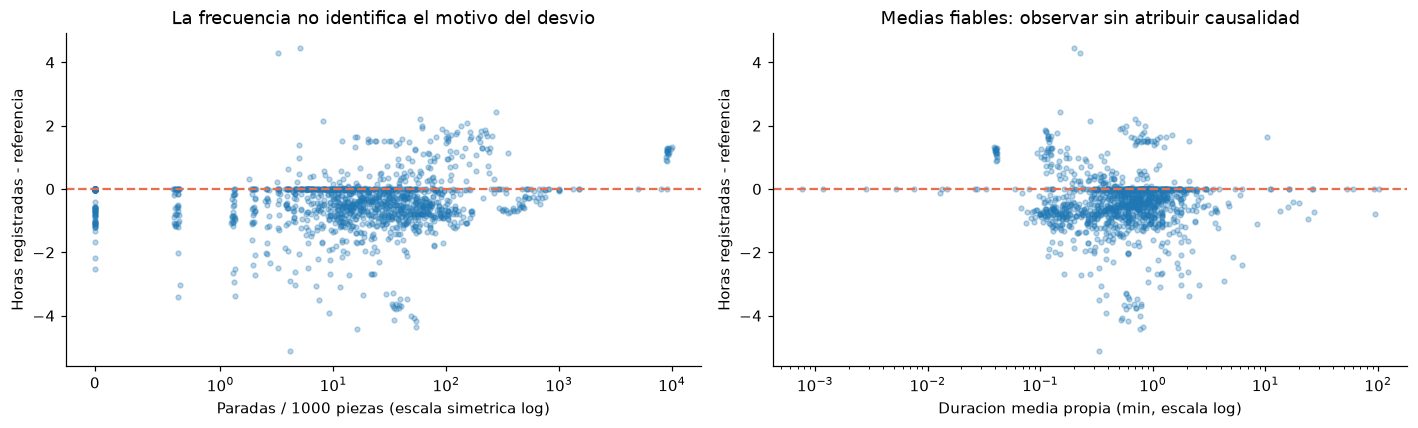

In [14]:
micro_clock = activity_clock.loc[activity_clock.NPR.gt(0) & activity_clock.TBF.gt(0)].copy()
micro_clock['fpm_clock'] = STOP_RATE_BASE * micro_clock.NAP / micro_clock.NPR
micro_clock['mean_stop_minutes_clock'] = 60 * micro_clock.TAP / micro_clock.NAP.where(micro_clock.NAP.gt(0))
reliable_clock_duration = (micro_clock.NAP.gt(0) & micro_clock.TAP.gt(0)
                            & ~micro_clock.stops_without_own_time & ~micro_clock.own_time_without_stops)
micro_clock['duration_group'] = np.select(
    [micro_clock.NAP.eq(0), ~reliable_clock_duration,
     micro_clock.mean_stop_minutes_clock.lt(1), micro_clock.mean_stop_minutes_clock.lt(2),
     micro_clock.mean_stop_minutes_clock.lt(15)],
    ['Sin paradas contadas', 'Contador/duracion por revisar', 'Media < 1 min', 'Media 1-2 min', 'Media 2-15 min'],
    default='Media >= 15 min')
micro_balance_groups = micro_clock.groupby('duration_group').agg(
    registros=('Jour','size'), mediana_desvio_absoluto_h=('abs_gap_hours','median'),
    por_debajo=('under_reference','sum'), por_encima=('over_reference','sum'),
    fuera_6min=('within_six_minutes',lambda s:(~s).sum()))
display(micro_balance_groups.round(3))
# Correlacion de Spearman mediante rangos: no requiere scipy ni supone relacion lineal.
clock_correlations = micro_clock[['gap_hours','abs_gap_hours','NAP','fpm_clock','mean_stop_minutes_clock']].rank().corr()
display(clock_correlations.round(3))
print('Ejemplos de deficit sin paradas registradas (NAP=0):')
display(micro_clock.loc[micro_clock.NAP.eq(0) & ~micro_clock.within_rounding, clock_detail_columns].head(12))
# Hipotesis contrafactual, NO estimacion de microparadas no registradas.
missing_counterfactual = micro_clock.loc[micro_clock.under_reference & ~micro_clock.within_rounding & micro_clock.NAP.gt(0)].copy()
missing_counterfactual['extra_minutes_per_counted_stop_if_all_gap_were_stops'] = -60 * missing_counterfactual.gap_hours / missing_counterfactual.NAP
print('Si TODO el deficit se debiera a esas mismas paradas contadas, haria falta sumar esta duracion por parada:')
display(missing_counterfactual.nsmallest(8,'gap_hours')[clock_detail_columns + ['extra_minutes_per_counted_stop_if_all_gap_were_stops']].round(3))
if len(micro_clock):
    fig, axes = plt.subplots(1,2,figsize=(13,4))
    axes[0].scatter(micro_clock.fpm_clock, micro_clock.gap_hours, s=10, alpha=.3)
    axes[0].set_xscale('symlog',linthresh=1)
    axes[0].set(xlabel=f'Paradas / {STOP_RATE_BASE} piezas (escala simetrica log)',ylabel='Horas registradas - referencia',title='La frecuencia no identifica el motivo del desvio')
    subset = micro_clock.loc[reliable_clock_duration]
    axes[1].scatter(subset.mean_stop_minutes_clock, subset.gap_hours, s=10, alpha=.3)
    axes[1].set_xscale('log')
    axes[1].set(xlabel='Duracion media propia (min, escala log)',ylabel='Horas registradas - referencia',title='Medias fiables: observar sin atribuir causalidad')
    for axis in axes: axis.axhline(0,color='#e76f51',linestyle='--')
    plt.tight_layout()
    plt.show()

## 7. Operaciones de ciclo elevado y esperas en otras operaciones

Una operacion lenta puede reducir el suministro aguas abajo (DES) y acumular producto
aguas arriba (SAT), dependiendo de las conexiones, capacidad de buffers y rutas paralelas.
**Aqui no se identifica una conexion real solo porque dos operaciones sean consecutivas.**

El ciclo TBF/NPR ya excluye TAP, DES y SAT: tener poca produccion por falta de suministro
no implica automaticamente un ciclo de funcionamiento alto. Antes de hablar de lentitud,
revisamos contadores, balance horario, produccion diaria y posibles repartos en paralelo.

,Linea,Operacion,Orden_OP,cycle_cmin,days_cycle_over_target,productive_days,NPR,min_daily_NPR,max_daily_NPR,pieces_vs_line_median,runtime_without_pieces,DES_pct,SAT_pct,days_within_6min,cycle_on_balanced_days
37,VLL_MONTAJE_L5,ST-0295,25,44404.390,13,13,41,0,10,0.002,3,2.184,11.152,15,41577.073
73,VLL_MONTAJE_L5,ST2376,72,178.890,16,16,11732,535,788,0.479,0,2.139,1.808,0,NaN
64,VLL_MONTAJE_L5,ST-2375,74,152.577,16,16,12454,672,974,0.509,0,2.373,4.565,2,162.759
44,VLL_MONTAJE_L5,ST-0830,79,85.271,16,16,24462,1469,1594,0.999,0,0.123,3.595,0,NaN
23,VLL_MONTAJE_L5,PM_0090,6,81.804,12,16,24854,1495,1612,1.015,0,1.891,5.025,0,NaN
89,VLL_MONTAJE_L5,ST_3100,82,81.206,14,16,24304,1466,1591,0.993,0,3.916,2.050,3,80.914
10,VLL_MONTAJE_L5,PM2110,47,80.780,13,16,23885,1427,1548,0.975,0,4.209,1.676,0,NaN


La ultima columna es una sensibilidad por seleccion de registros, no un ciclo corregido.
NPR muy bajo puede indicar contador incompleto, operacion opcional o un producto distinto.
Hipotesis de reparto de produccion, NO deteccion confirmada de paralelismo:


,Linea,Operacion_A,Operacion_B,Piezas_combinadas,Mediana_otras_operaciones,Ratio_combinado,Ciclo_equivalente_hipotetico
0,VLL_MONTAJE_L5,ST2376,ST-2375,24186,24489.0,0.988,82.345


El ciclo equivalente solo tendria sentido si ambas operaciones ejecutan el mismo paso en paralelo, con piezas y unidades comparables y ambas funcionando; requiere confirmar la topologia.


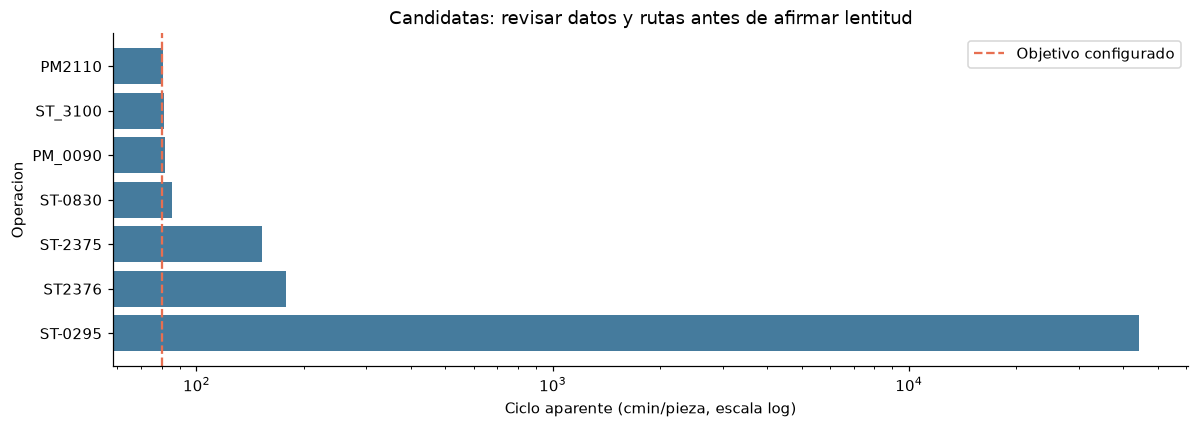

In [15]:
speed_days = activity_clock.copy()
speed_days['day_cycle_cmin'] = 6000 * speed_days.TBF / speed_days.NPR.where(speed_days.NPR.gt(0))
speed_days.loc[speed_days.production_without_runtime | speed_days.TBF.le(0),'day_cycle_cmin'] = np.nan
speed_period = speed_days.groupby(JOIN_KEYS + ['Orden_OP'],as_index=False)[VALUES].sum()
speed_period['cycle_cmin'] = 6000 * speed_period.TBF / speed_period.NPR.where(speed_period.NPR.gt(0))
speed_period['TR'] = speed_period[TIMES].sum(axis=1)
speed_period['DES_pct'] = 100 * speed_period.DES / speed_period.TR.where(speed_period.TR.gt(0))
speed_period['SAT_pct'] = 100 * speed_period.SAT / speed_period.TR.where(speed_period.TR.gt(0))
speed_period['mean_pieces_day'] = speed_period.NPR / speed_days.groupby(JOIN_KEYS).size().reindex(pd.MultiIndex.from_frame(speed_period[JOIN_KEYS])).to_numpy()
valid_outputs = speed_period.loc[speed_period.NPR.gt(0) & speed_period.TBF.gt(0)]
line_output_reference = valid_outputs.groupby('Linea').NPR.median().rename('median_operation_pieces')
speed_period = speed_period.join(line_output_reference,on='Linea')
speed_period['pieces_vs_line_median'] = speed_period.NPR / speed_period.median_operation_pieces
profile = speed_days.groupby(JOIN_KEYS).agg(
    observed_days=('Jour','size'), productive_days=('NPR',lambda s:s.gt(0).sum()),
    days_cycle_over_target=('day_cycle_cmin',lambda s:s.gt(CYCLE_TARGET_CMIN).sum()),
    runtime_without_pieces=('runtime_without_production','sum'),
    production_without_runtime_days=('production_without_runtime','sum'),
    days_within_6min=('within_six_minutes','sum'),
    min_daily_NPR=('NPR','min'),max_daily_NPR=('NPR','max'))
speed_period = speed_period.merge(profile,on=JOIN_KEYS,validate='one_to_one')
balanced_speed = speed_days.loc[speed_days.within_six_minutes].groupby(JOIN_KEYS)[['TBF','NPR']].sum()
balanced_speed['cycle_on_balanced_days'] = 6000 * balanced_speed.TBF / balanced_speed.NPR.where(balanced_speed.NPR.gt(0))
speed_period = speed_period.merge(balanced_speed[['cycle_on_balanced_days']],on=JOIN_KEYS,how='left',validate='one_to_one')
slow_profile = speed_period.loc[speed_period.cycle_cmin.gt(CYCLE_TARGET_CMIN) & speed_period.production_without_runtime_days.eq(0)].sort_values('cycle_cmin',ascending=False)
slow_columns = ['Linea','Operacion','Orden_OP','cycle_cmin','days_cycle_over_target','productive_days',
                'NPR','min_daily_NPR','max_daily_NPR','pieces_vs_line_median','runtime_without_pieces',
                'DES_pct','SAT_pct','days_within_6min','cycle_on_balanced_days']
display(slow_profile[slow_columns].round(3))
print('La ultima columna es una sensibilidad por seleccion de registros, no un ciclo corregido.')
print('NPR muy bajo puede indicar contador incompleto, operacion opcional o un producto distinto.')
# Una produccion cercana a la mitad merece revisar rutas antes de comparar con una estacion serial.
from itertools import combinations
parallel_hypotheses=[]
for line, group in slow_profile.loc[slow_profile.pieces_vs_line_median.between(.35,.65)].groupby('Linea'):
    for (_,a),(_,b) in combinations(group.iterrows(),2):
        reference_outputs=valid_outputs.loc[valid_outputs.Linea.eq(line) & ~valid_outputs.Operacion.isin([a.Operacion,b.Operacion]),'NPR'].median()
        ratio=(a.NPR+b.NPR)/reference_outputs
        if .8 <= ratio <= 1.2:
            parallel_hypotheses.append({'Linea':line,'Operacion_A':a.Operacion,'Operacion_B':b.Operacion,
                'Piezas_combinadas':a.NPR+b.NPR,'Mediana_otras_operaciones':reference_outputs,
                'Ratio_combinado':ratio,'Ciclo_equivalente_hipotetico':1/(1/a.cycle_cmin+1/b.cycle_cmin)})
parallel_hypotheses=pd.DataFrame(parallel_hypotheses)
print('Hipotesis de reparto de produccion, NO deteccion confirmada de paralelismo:')
display(parallel_hypotheses.round(3))
print('El ciclo equivalente solo tendria sentido si ambas operaciones ejecutan el mismo paso en paralelo, '
      'con piezas y unidades comparables y ambas funcionando; requiere confirmar la topologia.')
if not slow_profile.empty:
    fig,ax=plt.subplots(figsize=(11,4))
    ax.barh(slow_profile.Operacion,slow_profile.cycle_cmin,color='#457b9d')
    ax.axvline(CYCLE_TARGET_CMIN,linestyle='--',color='#e76f51',label='Objetivo configurado')
    ax.set_xscale('log')
    ax.set(xlabel='Ciclo aparente (cmin/pieza, escala log)',ylabel='Operacion',title='Candidatas: revisar datos y rutas antes de afirmar lentitud')
    ax.legend()
    plt.tight_layout()
    plt.show()

### 7.1 Coincidencia temporal con DES y SAT: busqueda guiada, no causalidad

Si se aporta `CONNECTIONS_PATH` con `Linea, Origen, Destino`, se estudia SAT en
alimentadoras directas y DES en receptoras directas de cada candidata lenta.

Sin esa tabla, mostramos exclusivamente una **lista de inspeccion**: la operacion
anterior y posterior en el orden, comparando DES y SAT en ambas. No se dibujan conexiones,
no se llama aguas arriba/abajo a esas filas y no se incorporan como responsables al ranking.
Puede haber paralelos y buffers. Con tan pocos dias y varias comparaciones, correlaciones
altas pueden aparecer por azar o por una causa comun; no son contrastes confirmatorios.

In [16]:
slow_links = None
if CONNECTIONS_PATH is not None:
    slow_links = pd.read_csv(CONNECTIONS_PATH, **CSV_OPTIONS).rename(columns=lambda col:col.strip())
    required_links=['Linea','Origen','Destino']
    if not set(required_links).issubset(slow_links.columns):
        raise ValueError('Conexiones: faltan Linea, Origen o Destino.')
    for col in required_links: slow_links[col]=slow_links[col].astype('string').str.strip()
    known_operations=set(map(tuple,config[JOIN_KEYS].to_numpy()))
    if slow_links[required_links].isna().any().any() or any((r.Linea,r.Origen) not in known_operations or (r.Linea,r.Destino) not in known_operations for r in slow_links.itertuples()):
        raise ValueError('Conexiones con identificadores desconocidos o incompletos.')
    slow_links=slow_links.drop_duplicates(required_links)

def rank_correlation(x,y):
    paired=pd.concat([x,y],axis=1).dropna()
    if len(paired)<6 or paired.iloc[:,0].nunique()<2 or paired.iloc[:,1].nunique()<2:
        return np.nan
    return paired.iloc[:,0].rank().corr(paired.iloc[:,1].rank())

slow_pairs=[]
slow_pair_days={}
for candidate in slow_profile.itertuples():
    own=speed_days.loc[speed_days.Linea.eq(candidate.Linea)&speed_days.Operacion.eq(candidate.Operacion)].copy()
    own=own.loc[own.day_cycle_cmin.notna()]
    checks=[]
    supplied = slow_links is not None and not slow_links.loc[slow_links.Linea.eq(candidate.Linea)].empty
    if supplied:
        line_links=slow_links.loc[slow_links.Linea.eq(candidate.Linea)]
        checks += [(name,'SAT','Enlace aportado: alimenta a la candidata') for name in line_links.loc[line_links.Destino.eq(candidate.Operacion),'Origen']]
        checks += [(name,'DES','Enlace aportado: recibe de la candidata') for name in line_links.loc[line_links.Origen.eq(candidate.Operacion),'Destino']]
    else:
        ordered=config.loc[config.Linea.eq(candidate.Linea)].sort_values(['Orden_OP','Operacion']).reset_index(drop=True)
        position=ordered.index[ordered.Operacion.eq(candidate.Operacion)][0]
        for pos in [position-1,position+1]:
            if 0<=pos<len(ordered):
                for kind in ['DES','SAT']:
                    checks.append((ordered.iloc[pos].Operacion,kind,'Vecindad de orden: NO es un enlace validado'))
    for other,kind,relation in checks:
        target=speed_days.loc[speed_days.Linea.eq(candidate.Linea)&speed_days.Operacion.eq(other),DAY_KEYS+[kind,'total_hours_exact','within_six_minutes','production_without_runtime']].copy()
        target=target.loc[~target.production_without_runtime & target.total_hours_exact.gt(0)]
        target['other_signal_pct']=100*target[kind]/target.total_hours_exact
        pair=own[DAY_KEYS+['day_cycle_cmin','within_six_minutes']].merge(
            target[DAY_KEYS+[kind,'other_signal_pct','within_six_minutes']],on=DAY_KEYS,how='inner',validate='one_to_one',suffixes=('_candidate','_other'))
        if pair.empty:continue
        pair['slow_day']=pair.day_cycle_cmin.gt(CYCLE_TARGET_CMIN)
        pair['both_balanced']=pair.within_six_minutes_candidate & pair.within_six_minutes_other
        nslow=int(pair.slow_day.sum()); nnormal=int((~pair.slow_day).sum())
        mean_slow=pair.loc[pair.slow_day,'other_signal_pct'].mean()
        mean_normal=pair.loc[~pair.slow_day,'other_signal_pct'].mean()
        rho=rank_correlation(pair.day_cycle_cmin,pair.other_signal_pct)
        strict=pair.loc[pair.both_balanced]
        slow_pairs.append({'Linea':candidate.Linea,'Candidata_lenta':candidate.Operacion,'Operacion_observada':other,
            'Senal':kind,'Relacion':relation,'Dias_pareados':len(pair),'Dias_ciclo_alto':nslow,'Dias_ciclo_normal':nnormal,
            'Espera_pct_con_ciclo_alto':mean_slow,'Espera_pct_con_ciclo_normal':mean_normal,
            'Diferencia_pp':mean_slow-mean_normal,'Spearman':rho,'Dias_ambas_balanceadas_6min':int(pair.both_balanced.sum()),
            'Spearman_balanceadas':rank_correlation(strict.day_cycle_cmin,strict.other_signal_pct),
            'Puede_comparar_alto_vs_normal':nslow>=3 and nnormal>=3})
        slow_pair_days[(candidate.Linea,candidate.Operacion,other,kind)]=pair
slow_pairs=pd.DataFrame(slow_pairs)
if not slow_pairs.empty:
    print('Resultados completos: las esperas pertenecen a la otra operacion, no a la candidata lenta.')
    with pd.option_context('display.max_rows',None,'display.max_columns',None):
        display(slow_pairs.sort_values('Spearman',ascending=False,na_position='last').round(3))
    print('Solo es posible contrastar dias lentos frente a normales si existen suficientes dias de ambos tipos:')
    display(slow_pairs.loc[slow_pairs.Puede_comparar_alto_vs_normal].round(3))
else:
    print('No hay parejas con datos suficientes. Aportar conexiones o ampliar el periodo.')

Resultados completos: las esperas pertenecen a la otra operacion, no a la candidata lenta.


,Linea,Candidata_lenta,Operacion_observada,Senal,Relacion,Dias_pareados,Dias_ciclo_alto,Dias_ciclo_normal,Espera_pct_con_ciclo_alto,Espera_pct_con_ciclo_normal,Diferencia_pp,Spearman,Dias_ambas_balanceadas_6min,Spearman_balanceadas,Puede_comparar_alto_vs_normal
18,VLL_MONTAJE_L5,PM_0090,ST_0095,DES,Vecindad de orden: NO es un enlace validado,16,12,4,4.429,2.380,2.050,0.788,0,NaN,True
13,VLL_MONTAJE_L5,ST-0830,ST_0820,SAT,Vecindad de orden: NO es un enlace validado,16,16,0,3.892,NaN,NaN,0.724,0,NaN,False
10,VLL_MONTAJE_L5,ST-2375,ST-2390,DES,Vecindad de orden: NO es un enlace validado,16,16,0,10.207,NaN,NaN,0.620,0,NaN,False
14,VLL_MONTAJE_L5,ST-0830,ST-0840,DES,Vecindad de orden: NO es un enlace validado,16,16,0,14.797,NaN,NaN,0.394,0,NaN,False
8,VLL_MONTAJE_L5,ST-2375,ST-2380,DES,Vecindad de orden: NO es un enlace validado,16,16,0,6.651,NaN,NaN,0.353,1,NaN,False
5,VLL_MONTAJE_L5,ST2376,ST-2360,SAT,Vecindad de orden: NO es un enlace validado,16,16,0,1.996,NaN,NaN,0.299,0,NaN,False
7,VLL_MONTAJE_L5,ST2376,ST-2380,SAT,Vecindad de orden: NO es un enlace validado,16,16,0,1.091,NaN,NaN,0.244,0,NaN,False
22,VLL_MONTAJE_L5,ST_3100,ST3100_2,DES,Vecindad de orden: NO es un enlace validado,16,14,2,2.756,2.596,0.161,0.191,3,NaN,False
6,VLL_MONTAJE_L5,ST2376,ST-2380,DES,Vecindad de orden: NO es un enlace validado,16,16,0,6.651,NaN,NaN,0.184,0,NaN,False
27,VLL_MONTAJE_L5,PM2110,PM2120,SAT,Vecindad de orden: NO es un enlace validado,16,13,3,2.561,2.929,-0.367,0.165,0,NaN,True


Solo es posible contrastar dias lentos frente a normales si existen suficientes dias de ambos tipos:


,Linea,Candidata_lenta,Operacion_observada,Senal,Relacion,Dias_pareados,Dias_ciclo_alto,Dias_ciclo_normal,Espera_pct_con_ciclo_alto,Espera_pct_con_ciclo_normal,Diferencia_pp,Spearman,Dias_ambas_balanceadas_6min,Spearman_balanceadas,Puede_comparar_alto_vs_normal
16,VLL_MONTAJE_L5,PM_0090,ST-0050,DES,Vecindad de orden: NO es un enlace validado,16,12,4,9.221,8.695,0.526,0.138,0,NaN,True
17,VLL_MONTAJE_L5,PM_0090,ST-0050,SAT,Vecindad de orden: NO es un enlace validado,16,12,4,9.836,10.279,-0.442,-0.141,0,NaN,True
18,VLL_MONTAJE_L5,PM_0090,ST_0095,DES,Vecindad de orden: NO es un enlace validado,16,12,4,4.429,2.380,2.050,0.788,0,NaN,True
19,VLL_MONTAJE_L5,PM_0090,ST_0095,SAT,Vecindad de orden: NO es un enlace validado,16,12,4,6.096,7.775,-1.678,-0.403,0,NaN,True
24,VLL_MONTAJE_L5,PM2110,ST-2100,DES,Vecindad de orden: NO es un enlace validado,16,13,3,2.100,2.336,-0.236,0.103,0,NaN,True
25,VLL_MONTAJE_L5,PM2110,ST-2100,SAT,Vecindad de orden: NO es un enlace validado,16,13,3,3.060,3.064,-0.003,0.144,0,NaN,True
26,VLL_MONTAJE_L5,PM2110,PM2120,DES,Vecindad de orden: NO es un enlace validado,16,13,3,4.112,4.652,-0.540,-0.285,0,NaN,True
27,VLL_MONTAJE_L5,PM2110,PM2120,SAT,Vecindad de orden: NO es un enlace validado,16,13,3,2.561,2.929,-0.367,0.165,0,NaN,True


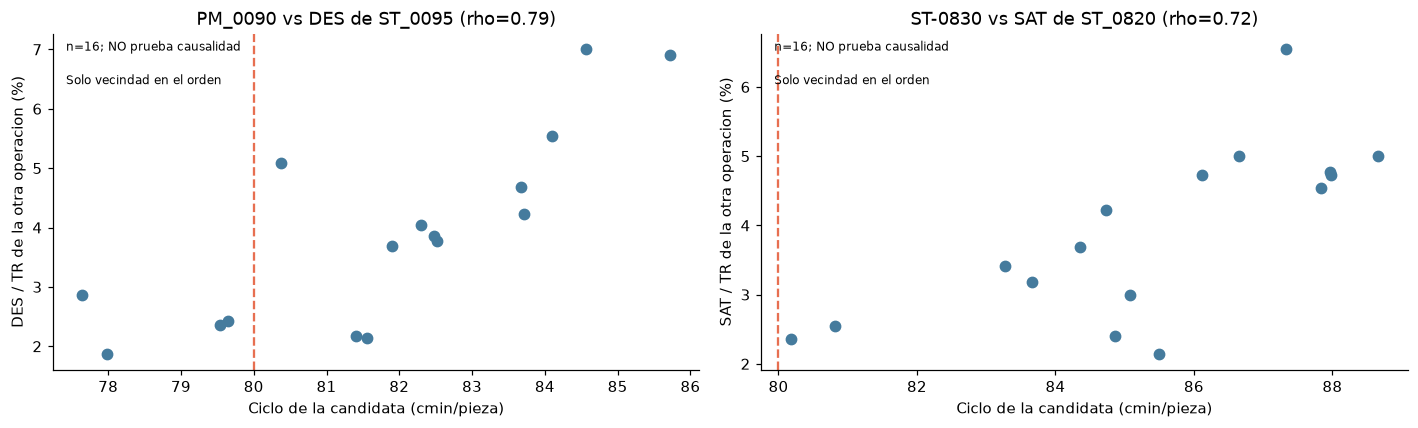

Conclusiones permitidas: localizar registros y candidatas a comprobar.
Conclusiones NO permitidas: confirmar conexiones, asignar culpa, estimar buffers o piezas finales perdidas.


In [17]:
# Mostrar por tipo la mayor asociacion exploratoria observada; no presupone que sea causal.
if not slow_pairs.empty:
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    for axis,kind in zip(axes,['DES','SAT']):
        choices=slow_pairs.loc[slow_pairs.Senal.eq(kind)&slow_pairs.Spearman.notna()].sort_values('Spearman',ascending=False)
        if choices.empty:
            axis.text(.5,.5,'Sin variacion suficiente',ha='center',va='center')
            continue
        row=choices.iloc[0]
        pair=slow_pair_days[(row.Linea,row.Candidata_lenta,row.Operacion_observada,kind)]
        axis.scatter(pair.day_cycle_cmin,pair.other_signal_pct,color='#457b9d',s=45)
        axis.axvline(CYCLE_TARGET_CMIN,color='#e76f51',linestyle='--')
        axis.set(title=f'{row.Candidata_lenta} vs {kind} de {row.Operacion_observada} (rho={row.Spearman:.2f})',
                 xlabel='Ciclo de la candidata (cmin/pieza)',ylabel=f'{kind} / TR de la otra operacion (%)')
        axis.text(.02,.98,f'n={len(pair)}; NO prueba causalidad',transform=axis.transAxes,va='top',fontsize=8)
        if 'NO es un enlace' in row.Relacion:
            axis.text(.02,.88,'Solo vecindad en el orden',transform=axis.transAxes,va='top',fontsize=8)
    plt.tight_layout()
    plt.show()
print('Conclusiones permitidas: localizar registros y candidatas a comprobar.')
print('Conclusiones NO permitidas: confirmar conexiones, asignar culpa, estimar buffers o piezas finales perdidas.')

In [18]:
clock_interpretation = []
clock_interpretation.append({'Tema':'Balance nominal',
    'Hecho':f'{int(clock_audit.exact_reference.sum())}/{len(clock_audit)} registros exactos; {int(clock_audit.under_reference.sum())} inferiores y {int(clock_audit.over_reference.sum())} superiores.',
    'Interpretacion':'No se puede imponer una jornada uniforme de 22 h sin revisar captura y planificacion. La media global ocultaria diferencias.'})
clock_interpretation.append({'Tema':'Precision y tolerancia',
    'Hecho':f'{int((~clock_audit.within_rounding).sum())} registros superan el limite condicional de redondeo; {len(clock_boundary_cases)} marcas de frontera cambian con suma decimal exacta.',
    'Interpretacion':'Los grandes desvios no se explican solo por representar cuatro numeros a dos decimales; seis minutos no se deducen de esa precision.'})
for (line,operation), row in clock_activity_summary.loc[clock_activity_summary.tiempos_cero.gt(0)].iterrows():
    clock_interpretation.append({'Tema':'Sin tiempo asignado','Hecho':f'{line}/{operation}: {int(row.tiempos_cero)} jornadas con total cero.',
        'Interpretacion':'Confirmar si estaba fuera de servicio o si falta el registro. No afirmar averia ni tiempo recuperable.'})
if len(micro_clock):
    rho=clock_correlations.loc['fpm_clock','abs_gap_hours']
    clock_interpretation.append({'Tema':'Hipotesis de microparadas','Hecho':f'Asociacion descriptiva FPM vs desvio absoluto: rho={rho:.3f}.',
        'Interpretacion':'Las paradas ya registradas en TAP estan sumadas. No demuestra que el hueco provenga de microparadas omitidas, y no explica excesos de horas.'})
clock_interpretation.append({'Tema':'Ciclo aparente', 'Hecho':f'{len(slow_profile)} operaciones superan el objetivo; {len(parallel_hypotheses)} parejas sugieren comprobar reparto de piezas.',
    'Interpretacion':'Validar NPR, unidades, jornada y rutas antes de concluir que limitan la linea.'})
clock_interpretation.append({'Tema':'Esperas en otras operaciones',
    'Hecho':f'{len(slow_pairs)} comparaciones exploratorias; topologia aportada: {slow_links is not None}.',
    'Interpretacion':'La asociacion diaria puede guiar una inspeccion. Sin conexiones y eventos temporales no demuestra DES/SAT causados por una maquina lenta.'})
display(pd.DataFrame(clock_interpretation))

,Tema,Hecho,Interpretacion
0,Balance nominal,512/1820 registros exactos; 1075 inferiores y ...,No se puede imponer una jornada uniforme de 22...
1,Precision y tolerancia,1098 registros superan el limite condicional d...,Los grandes desvios no se explican solo por re...
2,Sin tiempo asignado,VLL_MONTAJE_L5/ST_0030: 16 jornadas con total ...,Confirmar si estaba fuera de servicio o si fal...
3,Hipotesis de microparadas,Asociacion descriptiva FPM vs desvio absoluto:...,Las paradas ya registradas en TAP estan sumada...
4,Ciclo aparente,7 operaciones superan el objetivo; 1 parejas s...,"Validar NPR, unidades, jornada y rutas antes d..."
5,Esperas en otras operaciones,28 comparaciones exploratorias; topologia apor...,La asociacion diaria puede guiar una inspeccio...


## 8. Conclusiones que admite este analisis

1. **La planificacion define la exposicion al riesgo.** Un cierre registrado como TAP
   puede hacer parecer poco fiable a una maquina que no tenia que producir.
2. **Calidad y fiabilidad industrial son cuestiones distintas.** Un contador inconsistente
   necesita revision del dato; no es evidencia suficiente de una averia.
3. **Las perdidas propias y las esperas requieren actuaciones diferentes.** TAP orienta
   mantenimiento de la operacion; DES/SAT orientan investigacion de flujo y suministro.
4. **Frecuencia, duracion y recurrencia se complementan.** Muchas interrupciones breves
   y pocas averias largas pueden acumular el mismo TAP y necesitar soluciones diferentes.
5. **Los agregados identifican candidatos, no causas demostradas.** Las ramas paralelas,
   los buffers y el desfase temporal impiden atribuir propagacion usando solo el orden.
6. **Prevenir exige seguimiento.** Tras intervenir, comparar periodos con planificacion
   y mezcla de producto similares. Cuatro semanas no bastan para predecir fallos.

No se calcula un indice de culpa ni se equiparan horas-maquina con produccion final
recuperable. Tampoco se exige que todas las filas sumen 22 horas ni se borran todos
los registros sin funcionamiento.

In [19]:
print('RESUMEN DE LA EXPLORACION')
print(f'{len(raw_data)} registros originales; {len(clean)} utilizables; {len(quarantine)} apartados.')
print(f'{int(audit["identical_copies_removed"])} copias identicas retiradas sin sumar sus valores.')
print(f'{int(days.day_status.eq("sin_actividad_por_confirmar").sum())} dias-linea sin actividad por confirmar.')
print(f'{int(days.day_status.eq("cierre_confirmado").sum())} dias-linea con cierre confirmado por calendario.')
print(f'{len(active)} operaciones comparables y {len(priorities)} bajo el objetivo en el escenario provisional.')
print(f'{len(slow_cycles)} operaciones con ciclo superior al objetivo, sujeto a unidades y validez del contador.')
print(f'{int(stop_candidates.short_frequent_signal.sum())} senales exploratorias de interrupciones frecuentes y breves.')
print('Antes de decidir: confirmar calendario, actividad prevista por operacion, unidades y semantica de contadores.')

RESUMEN DE LA EXPLORACION
1820 registros originales; 1820 utilizables; 0 apartados.
0 copias identicas retiradas sin sumar sus valores.
4 dias-linea sin actividad por confirmar.
0 dias-linea con cierre confirmado por calendario.
84 operaciones comparables y 5 bajo el objetivo en el escenario provisional.
7 operaciones con ciclo superior al objetivo, sujeto a unidades y validez del contador.
19 senales exploratorias de interrupciones frecuentes y breves.
Antes de decidir: confirmar calendario, actividad prevista por operacion, unidades y semantica de contadores.


## Alcance y reutilizacion

Para otros datos, cambiar las rutas y los mapas de columnas; confirmar la granularidad
diaria, las unidades y el significado de los contadores; aportar calendario de fabrica;
y configurar objetivos adecuados a cada linea. Los valores 22 horas, 90 %, 80 cmin
y 60 segundos son parametros de este caso, no constantes universales.

La cobertura solo se puede evaluar contra un universo conocido: el calendario puede
revelar dias completamente ausentes; sin el, no sabemos si faltan jornadas enteras.
La configuracion describe operaciones posibles, no garantiza que todas tuvieran que
producir ese periodo. Si hay turnos, productos o ramas con objetivos distintos,
incorporar esas dimensiones antes de comparar.

Entrega minima futura: `cleaning.py` para preparar y auditar; `analysis.py` para
indicadores y graficas; este notebook para documentar decisiones. Sin interfaz.